In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np

# Charger tous les fichiers
parcelle = pd.read_csv("/content/drive/MyDrive/zakaria data2/Parcellaire.csv")
npk = pd.read_csv("/content/drive/MyDrive/zakaria data2/Apports N.P.K.csv")
irrigation = pd.read_csv("/content/drive/MyDrive/zakaria data2/Irrigation.csv")
irrigation_2 = pd.read_csv("/content/drive/MyDrive/zakaria data2/Irrigation_2.csv")
irrigation_3 = pd.read_csv("/content/drive/MyDrive/zakaria data2/Irrigation_3.csv")
irrigation_4 = pd.read_csv("/content/drive/MyDrive/zakaria data2/Irrigation_4.csv")
irrigation_5 = pd.read_csv("/content/drive/MyDrive/zakaria data2/Irrigation_5.csv")
bd_climat = pd.read_excel("/content/drive/MyDrive/zakaria data2/BD_Climat_Domaines.xlsx", sheet_name=0)
train = pd.read_csv("/content/drive/MyDrive/zakaria data2/train.csv")
test = pd.read_csv("/content/drive/MyDrive/zakaria data2/test.csv")
bd_domaines = pd.read_excel("/content/drive/MyDrive/zakaria data2/BD_Climat_Domaines.xlsx", sheet_name=2)

In [3]:
print("Parcelle columns:", parcelle.columns.tolist())
print("irrigation columns:", irrigation.columns.tolist())
print("npk columns:", npk.columns.tolist())
print("train columns:", train.columns.tolist())

Parcelle columns: ['Campagne', 'Region', 'Code Ferme', 'Libelle Site', 'Libelle Variete', 'Num Parcelle', 'CodeTracabilite', 'Date Plantation', 'Date Arrachage', 'Porte Greffe', 'Sup Debut Camp', 'Sup Plantee', 'Sup Arrachee', 'Sup Fin Camp']
irrigation columns: ['Campagne', 'Region', 'Code Ferme', 'Libelle Site', 'Libelle Variete', 'Num Parcelle', 'Code Traçabilité', 'Date', 'Qté eau (m3)']
npk columns: ['Campagne', 'Region', 'Code Ferme', 'Libelle Site', 'Libelle Variete', 'Num Parcelle', 'CodeTracabilite', 'Date', 'N', 'P', 'K']
train columns: ['id', 'Campagne', 'Region', 'Code Ferme', 'Libelle Site', 'Libelle Variete', 'Num Parcelle', 'CodeTracabilite', 'Date', 'Tonnage (Kg)']


In [4]:
npk ['Libelle Site'].unique()

array(['Site 1', 'Site 3', 'Site 4', 'Site 5', 'Site 6', 'Site 7',
       'Site 9', 'Site 10', 'Site 13', 'Site 14', 'Site 15', 'Ferme 16',
       'Site 17', 'Site 18', 'Site 19', 'Site 20', 'Site 21', 'Site 22',
       'Site 8', 'Site 11', 'Site 24', 'Site 12', 'Site 26'], dtype=object)

In [5]:
train ['Libelle Site'].unique()

array(['Site 1', 'Site 3', 'Site 4', 'Site 5', 'Site 6', 'Site 7',
       'Site 8', 'Site 9', 'Site 10', 'Site 11', 'Site 12', 'Site 13',
       'Site 14', 'Site 15', 'Ferme 16', 'Site 17', 'Site 18', 'Site 19',
       'Site 20', 'Site 21', 'Site 22'], dtype=object)

In [6]:
test ['Libelle Site'].unique()

array(['Site 3', 'Site 4', 'Site 6', 'Site 7', 'Site 9', 'Site 10',
       'Site 11', 'Site 12', 'Site 13', 'Site 14', 'Site 15', 'Ferme 16',
       'Site 17', 'Site 18', 'Site 19', 'Site 20', 'Site 21', 'Site 22'],
      dtype=object)

In [7]:
parcelle ['Libelle Site'].unique()

array(['Site 1', 'Site 2', 'Site 3', 'Site 4', 'Site 5', 'Site 6',
       'Site 7', 'Site 8', 'Site 9', 'Site 10', 'Site 11', 'Site 12',
       'Site 13', 'Site 14', 'Site 15', 'Ferme 16', 'Site 17', 'Site 18',
       'Site 19', 'Site 20', 'Site 21', 'Site 22', 'Site 23', 'Site 24',
       'Site 25', 'Site 26'], dtype=object)

In [8]:
irrigation ['Libelle Site'].unique()

array(['Site 1', 'Site 3', 'Site 4', 'Site 5', 'Site 6', 'Site 7',
       'Site 9', 'Site 10', 'Site 13', 'Site 14', 'Site 15', 'Ferme 16',
       'Site 17', 'Site 18', 'Site 19', 'Site 20', 'Site 21', 'Site 22',
       'Site 24', 'Site 8'], dtype=object)

In [9]:
bd_domaines ['LibelleFerme'].unique()

array(['ADM TIDDAS', 'AFOURER', 'AGAFAI', 'AGDAL', 'AGOURAI', 'AIN CHAIB',
       'AIN HAMRA', 'AIN ITTO AOMAR', 'AIT OUALLAL', 'ALLAMIA',
       'BOUDERRA', 'EL BAHJA I', 'EL BAHJA II', 'GRAOUA', 'HAMMA',
       'JNANE LAKBIR', 'JORF I', 'JORF II', 'KHOUALKA', 'LA LAURE',
       'MENARA', 'MHATTA', 'NOUASSER', 'NOUR', 'ONAGRI', 'OUARGHA',
       'OULED ABDELLAH', 'OULED GNAOU', 'PALMIER DATTIER', 'SAOUDA',
       'SIDI EL KAMEL 1', 'SIDI EL KAMEL 2', 'SIDI MOUSSA', 'SOUIHLA',
       'STAH LAMDINA', 'TRIFFA', 'ADM SIDI SLIMANE', 'AGADIR BIO',
       'BELFAA', 'OULED AYAD F.R.', 'ADM KELAAT MEGOUNA', 'DAR ESSALAM',
       'ADM MAAZIZ', 'CHERIFIA', 'MNASRA FLEG', 'AMSENJI',
       'OULED AYAD ARBO'], dtype=object)

In [10]:
bd_climat ['nom_domaine'].unique()

array(['NOUACEUR', 'DAKHLA1', 'DAKHLA2', 'PALMIER DATTIER', 'ADM MAAZIZ',
       'ADM TIDDAS', 'AIN ITTO AOMAR', 'AIT OUALLAL', 'BOUDERRA', 'HAMMA',
       'JORF I', 'MHATTA', 'MNASRA ARBO', 'OUARGHA', 'OULED AYAD F.R.',
       'PEPINIERE OULED TALEB', 'SIDI EL KAMEL 1', 'SIDI EL KAMEL 2',
       'SIDI YAHIA', 'AGAFAI', 'AGDAL', 'EL BAHJA I', 'GRAOUA',
       'KHOUALKA', 'TRIFFA', 'DAR ESSALAM', 'PEPINIERE SKHIRAT',
       'AGOURAI', 'AIN HAMRA', 'DOUIET CULTURES', 'ADM AGADIR',
       'AGADIR BIO', 'BELFAA', 'NOUR', 'SAOUDA', 'AFOURER', 'ALLAMIA',
       'BENI MELLAL BIO', 'OULED GNAOU', 'OULED ABDELLAH', 'STAH LAMDINA',
       'ADM KELAAT MEGOUNA'], dtype=object)

In [11]:
bd_climat.shape

(79926, 13)

In [12]:
import pandas as pd

# Règles (domaine manquant -> domaine donneur) d'après ton PDF
rules = {
    "JORF II": "JORF I",
    "EL BAHJA II": "EL BAHJA I",
    "JNANE LAKBIR": "EL BAHJA I",
    "AIN CHAIB": "NOUR",
    "LA LAURE": "NOUR",
    "QUALIAGRO PEPINIERE": "NOUR",
    "LA CHENAIE": "DAR ESSALAM",
    "ONAGRI": "KHOUALKA",
    # SIDI MOUSSA : Non (pas de donneur dans le doc) => on ne fait rien
}

def norm(x):
    return str(x).strip().upper()

bd_climat = bd_climat.copy()
bd_climat["_dom_"] = bd_climat["nom_domaine"].map(norm)

to_add = []
for missing_dom, donor_dom in rules.items():
    missing_k = norm(missing_dom)
    donor_k = norm(donor_dom)

    # Si le domaine "manquant" existe déjà -> on ne copie pas
    if (bd_climat["_dom_"] == missing_k).any():
        continue

    donor_rows = bd_climat.loc[bd_climat["_dom_"] == donor_k]
    if donor_rows.empty:
        print(f"⚠️ Donneur introuvable: '{donor_dom}' (pour créer '{missing_dom}')")
        continue

    new_rows = donor_rows.copy()
    new_rows["nom_domaine"] = missing_dom
    new_rows["_dom_"] = missing_k
    to_add.append(new_rows)

# Ajouter les lignes copiées
if to_add:
    bd_climat_completed = pd.concat([bd_climat, *to_add], ignore_index=True)
else:
    bd_climat_completed = bd_climat

# Nettoyage
bd_climat_completed = bd_climat_completed.drop(columns=["_dom_"])

print("✅ bd_climat avant :", bd_climat.shape[0])
print("✅ bd_climat après :", bd_climat_completed.shape[0])

# Optionnel : afficher les domaines ajoutés
added = set(bd_climat_completed["nom_domaine"].map(norm)) - set(bd_climat["nom_domaine"].map(norm))
print("➕ Domaines ajoutés :", sorted(added))



✅ bd_climat avant : 79926
✅ bd_climat après : 95150
➕ Domaines ajoutés : ['AIN CHAIB', 'EL BAHJA II', 'JNANE LAKBIR', 'JORF II', 'LA CHENAIE', 'LA LAURE', 'ONAGRI', 'QUALIAGRO PEPINIERE']


In [13]:
bd_domaines.shape

(1524, 6)

In [14]:
import pandas as pd

# Règles du PDF : domaine -> domaine dont on doit prendre les données climat
rules = {
    "JORF II": "JORF I",
    "EL BAHJA II": "EL BAHJA I",
    "JNANE LAKBIR": "EL BAHJA I",
    "AIN CHAIB": "NOUR",
    "LA LAURE": "NOUR",
    "QUALIAGRO PEPINIERE": "NOUR",
    "LA CHENAIE": "DAR ESSALAM",
    "ONAGRI": "KHOUALKA",
    # SIDI MOUSSA : Non => on laisse tel quel (pas de donneur)
}

def norm(x):
    return str(x).strip().upper()

bd_domaines = bd_domaines.copy()
bd_domaines["ferme_norm"] = bd_domaines["LibelleFerme"].map(norm)

# Colonne de travail : par défaut chaque ferme prend son propre climat
bd_domaines["climat_domaine"] = bd_domaines["ferme_norm"]

# Appliquer les remplacements selon le PDF
map_norm = {norm(k): norm(v) for k, v in rules.items()}
bd_domaines["climat_domaine"] = bd_domaines["climat_domaine"].replace(map_norm)

# (Optionnel) voir combien de lignes ont été redirigées
changed = bd_domaines[bd_domaines["climat_domaine"] != bd_domaines["ferme_norm"]]
print("✅ lignes redirigées:", changed.shape[0])
print(changed[["LibelleFerme", "climat_domaine"]].head(20))

# Nettoyage (si tu veux garder juste l'utile)
bd_domaines = bd_domaines.drop(columns=["ferme_norm"])


✅ lignes redirigées: 203
    LibelleFerme climat_domaine
17     AIN CHAIB           NOUR
18     AIN CHAIB           NOUR
19     AIN CHAIB           NOUR
20     AIN CHAIB           NOUR
21     AIN CHAIB           NOUR
56   EL BAHJA II     EL BAHJA I
57   EL BAHJA II     EL BAHJA I
58   EL BAHJA II     EL BAHJA I
59   EL BAHJA II     EL BAHJA I
67  JNANE LAKBIR     EL BAHJA I
68  JNANE LAKBIR     EL BAHJA I
72       JORF II         JORF I
73       JORF II         JORF I
74       JORF II         JORF I
75       JORF II         JORF I
80      LA LAURE           NOUR
81      LA LAURE           NOUR
82      LA LAURE           NOUR
83      LA LAURE           NOUR
84      LA LAURE           NOUR


In [15]:

bd_domaines.shape

(1524, 7)

In [16]:
# Dictionnaire de mapping
site_mapping = {
    'AIT OUALLAL': 'Site 1',
    'DAR ESSALAM': 'Site 2',
    'JORF I': 'Site 3',
    'JORF II': 'Site 4',
    'SIDI MOUSSA': 'Site 5',
    'OUARGHA': 'Site 6',
    'AGAFAI': 'Site 7',
    'AGDAL': 'Site 8',
    'EL BAHJA I': 'Site 9',
    'EL BAHJA II': 'Site 10',
    'GRAOUA': 'Site 11',
    'JNANE LAKBIR': 'Site 12',
    'TRIFFA': 'Site 13',
    'AIN CHAIB': 'Site 14',
    'LA LAURE': 'Site 15',
    'NOUR': 'Site 16',
    'OULED ABDELLAH': 'Site 17',
    'SAOUDA': 'Site 18',
    'STAH LAMDINA': 'Site 19',
    'AFOURER': 'Site 20',
    'ALLAMIA': 'Site 21',
    'OULED GNAOU': 'Site 22',
    'QUALIAGRO PEPINIERE': 'Site 23',
    'LA CHENAIE': 'Site 24',
    'PEPINIERE OULED TALEB': 'Site 25',
    'ONAGRI': 'Site 26'
}

# Application du mapping sur bd_Climat
bd_climat['nom_domaine'] = bd_climat['nom_domaine'].map(site_mapping)

# Application du mapping sur bd_Domaines
bd_domaines['LibelleFerme'] = bd_domaines['LibelleFerme'].map(site_mapping)

# Vérification
print("bd_Climat - Valeurs uniques après mapping:")
print(bd_climat['nom_domaine'].value_counts())
print("\nbd_Domaines - Valeurs uniques après mapping:")
print(bd_domaines['LibelleFerme'].value_counts())

bd_Climat - Valeurs uniques après mapping:
nom_domaine
Site 1     1903
Site 3     1903
Site 6     1903
Site 25    1903
Site 7     1903
Site 8     1903
Site 9     1903
Site 11    1903
Site 13    1903
Site 2     1903
Site 16    1903
Site 18    1903
Site 20    1903
Site 21    1903
Site 22    1903
Site 17    1903
Site 19    1903
Name: count, dtype: int64

bd_Domaines - Valeurs uniques après mapping:
LibelleFerme
Site 1     64
Site 9     63
Site 7     63
Site 22    60
Site 13    53
Site 8     50
Site 16    49
Site 19    48
Site 15    47
Site 14    47
Site 18    46
Site 10    45
Site 20    39
Site 17    38
Site 6     36
Site 21    35
Site 12    34
Site 4     29
Site 3     16
Site 5      9
Site 11     3
Site 2      2
Site 26     1
Name: count, dtype: int64


In [17]:
# Méthode 1 : rename() - recommandée
bd_climat = bd_climat.rename(columns={'nom_domaine': 'Libelle Site'})

# Ou sans réassignation (inplace)
bd_domaines.rename(columns={'LibelleFerme': 'Libelle Site'}, inplace=True)



In [18]:
# Vérification des missing values
import pandas as pd

# Exemple : si tes dataframes s'appellent parcelle, irrigation, npk

print("=== Parcelle ===")
print(parcelle.isnull().sum())

print("=== train ===")
print(train.isnull().sum())



print("\n=== Irrigation ===")
print(irrigation.isnull().sum())

print("\n=== Irrigation ===")
print(irrigation_2.isnull().sum())

print("\n=== Irrigation ===")
print(irrigation_3.isnull().sum())

print("\n=== Irrigation ===")
print(irrigation_4.isnull().sum())

print("\n=== Irrigation ===")
print(irrigation_5.isnull().sum())

print("\n=== NPK ===")
print(npk.isnull().sum())


=== Parcelle ===
Campagne            0
Region             12
Code Ferme          0
Libelle Site        0
Libelle Variete     0
Num Parcelle        0
CodeTracabilite    10
Date Plantation     0
Date Arrachage     20
Porte Greffe       28
Sup Debut Camp      0
Sup Plantee         0
Sup Arrachee        0
Sup Fin Camp        0
dtype: int64
=== train ===
id                 0
Campagne           0
Region             0
Code Ferme         0
Libelle Site       0
Libelle Variete    0
Num Parcelle       0
CodeTracabilite    0
Date               0
Tonnage (Kg)       0
dtype: int64

=== Irrigation ===
Campagne            0
Region              0
Code Ferme          0
Libelle Site        0
Libelle Variete     0
Num Parcelle        0
Code Traçabilité    0
Date                0
Qté eau (m3)        0
dtype: int64

=== Irrigation ===
Campagne            0
Region              0
Code Ferme          0
Libelle Site        0
Libelle Variete     0
Num Parcelle        0
Code Traçabilité    0
Date                

In [19]:
# Appliquer la logique: Si Sup Fin Camp > 0, sinon Sup Debut Camp
parcelle['Surface'] = np.where(
    parcelle['Sup Fin Camp'] > 0,
    parcelle['Sup Fin Camp'],
    parcelle['Sup Debut Camp']
)

# Vérifier les parcelles arrachées (Fin Camp = 0 mais Debut Camp > 0)
parcelles_arrachees = parcelle[
    (parcelle['Sup Fin Camp'] == 0) &
    (parcelle['Sup Debut Camp'] > 0)
]
print(f"✅ Parcelles arrachées identifiées: {len(parcelles_arrachees)}")
print(f"   (attendu: ~106 selon le guide)")

✅ Parcelles arrachées identifiées: 106
   (attendu: ~106 selon le guide)


In [20]:
# Identifier la parcelle problématique
parcelle_10040 = parcelle[
    (parcelle['Num Parcelle'] == '10040') &
    (parcelle['Campagne'] == '22/23')
]
print(f"Parcelle 10040 trouvée: {len(parcelle_10040)} ligne(s)")

# Exclure cette parcelle de TOUS les datasets
parcelle = parcelle[~((parcelle['Num Parcelle'] == '10040') &
                             (parcelle['Campagne'] == '22/23'))]
npk = npk[~((npk['Num Parcelle'] == '10040') &
                   (npk['Campagne'] == '22/23'))]
irrigation = irrigation[~((irrigation['Num Parcelle'] == '10040') &
                                 (irrigation['Campagne'] == '22/23'))]
irrigation_2 = irrigation_2[~((irrigation_2['Num Parcelle'] == '10040') &
                                 (irrigation_2['Campagne'] == '22/23'))]
irrigation_3 = irrigation_3[~((irrigation_3['Num Parcelle'] == '10040') &
                                 (irrigation_3['Campagne'] == '22/23'))]
irrigation_4 = irrigation_4[~((irrigation_4['Num Parcelle'] == '10040') &
                                 (irrigation_4['Campagne'] == '22/23'))]
irrigation_5 = irrigation_5[~((irrigation_5['Num Parcelle'] == '10040') &
                                 (irrigation_5['Campagne'] == '22/23'))]
train = train[~((train['Num Parcelle'] == '10040') &
                       (train['Campagne'] == '22/23'))]
test = test[~((test['Num Parcelle'] == '10040') &
                       (test['Campagne'] == '22/23'))]



print("✅ Parcelle 10040 exclue de tous les fichiers")

Parcelle 10040 trouvée: 1 ligne(s)
✅ Parcelle 10040 exclue de tous les fichiers


In [21]:
mask_irrig = (irrigation['Num Parcelle'] == 20106) & \
             (irrigation['Date'] == '2021-08-23')

print(f"Lignes à corriger: {mask_irrig.sum()}")
print(f"Valeur avant: {irrigation.loc[mask_irrig, 'Qté eau (m3)'].values}")

irrigation.loc[mask_irrig, 'Qté eau (m3)'] = 297

print(f"Valeur après: {irrigation.loc[mask_irrig, 'Qté eau (m3)'].values}")
print("✅ Irrigation corrigée")

Lignes à corriger: 1
Valeur avant: [182474.24930545]
Valeur après: [297.]
✅ Irrigation corrigée


In [22]:
# Conversion des dates en format datetime pour la recherche
npk['Date'] = pd.to_datetime(npk['Date'])

# Correction 1: Parcelle 15010, K = 215
mask1 = (npk['Num Parcelle'] == 15010) & \
        (npk['Date'] == '2024-09-30')
print(f"15010 K avant: {npk.loc[mask1, 'K'].values}")
npk.loc[mask1, 'K'] = 215
print(f"15010 K après: {npk.loc[mask1, 'K'].values}")

# Correction 2: Parcelle 30040, P = 300
mask2 = (npk['Num Parcelle'] == 30040) & \
        (npk['Date'] == '2025-02-28')
print(f"30040 P avant: {npk.loc[mask2, 'P'].values}")
npk.loc[mask2, 'P'] = 300
print(f"30040 P après: {npk.loc[mask2, 'P'].values}")

# Correction 3: Parcelle 30030, P = 596
mask3 = (npk['Num Parcelle'] == 30030) & \
        (npk['Date'] == '2025-03-01')
print(f"30030 P avant: {npk.loc[mask3, 'P'].values}")
npk.loc[mask3, 'P'] = 596
print(f"30030 P après: {npk.loc[mask3, 'P'].values}")

# Correction 4: Parcelle 30080, P = 596
mask4 = (npk['Num Parcelle'] == 30080) & \
        (npk['Date'] == '2025-02-27')
print(f"30080 P avant: {npk.loc[mask4, 'P'].values}")
npk.loc[mask4, 'P'] = 596
print(f"30080 P après: {npk.loc[mask4, 'P'].values}")

print("✅ 4 corrections NPK effectuées")

15010 K avant: [2154.99975]
15010 K après: [215.]
30040 P avant: [1370.7]
30040 P après: [300.]
30030 P avant: [1171.2]
30030 P après: [596.]
30080 P avant: [1179.3]
30080 P après: [596.]
✅ 4 corrections NPK effectuées


In [23]:
# Identifier les N négatifs
negatifs = npk[npk['N'] < 0]
print(f"N négatifs trouvés: {len(negatifs)}")
print(f"   (attendu: 8 à JNANE LAKBIR)")

# Remplacer par 0
npk.loc[npk['N'] < 0, 'N'] = 0

print("✅ N négatifs corrigés")

N négatifs trouvés: 8
   (attendu: 8 à JNANE LAKBIR)
✅ N négatifs corrigés


In [24]:
# Correction irrigation: 182474 → 297
mask_irrig = (irrigation['Num Parcelle'] == 20106) & \
             (irrigation['Date'] == '2021-08-23')

print(f"Lignes à corriger: {mask_irrig.sum()}")
print(f"Valeur avant: {irrigation.loc[mask_irrig, 'Qté eau (m3)'].values}")

irrigation.loc[mask_irrig, 'Qté eau (m3)'] = 297

print(f"Valeur après: {irrigation.loc[mask_irrig, 'Qté eau (m3)'].values}")
print("✅ Irrigation corrigée")

Lignes à corriger: 1
Valeur avant: [297.]
Valeur après: [297.]
✅ Irrigation corrigée


In [25]:
# Identifier les N négatifs
negatifs = npk[npk['N'] < 0]
print(f"N négatifs trouvés: {len(negatifs)}")
print(f"   (attendu: 8 à JNANE LAKBIR)")

# Remplacer par 0
npk.loc[npk['N'] < 0, 'N'] = 0

print("✅ N négatifs corrigés")

N négatifs trouvés: 0
   (attendu: 8 à JNANE LAKBIR)
✅ N négatifs corrigés


In [26]:
KEY = ["Num Parcelle", "Campagne"]


In [27]:
train_base = train.copy()
test_base = test.copy()

print(train_base.shape)  # doit rester 1629
print(test_base.shape)   # doit rester 411

(1629, 10)
(411, 10)


In [28]:
parc_agg = parcelle.drop_duplicates(subset=KEY)

# Convert 'Num Parcelle' and 'Campagne' to string type in train_base and test_base
# to ensure compatibility with parcelle_reduced during merge
train_base['Num Parcelle'] = train_base['Num Parcelle'].astype(str)
test_base['Num Parcelle'] = test_base['Num Parcelle'].astype(str)
train_base['Campagne'] = train_base['Campagne'].astype(str)
test_base['Campagne'] = test_base['Campagne'].astype(str)
train_base['Libelle Site'] = train_base['Libelle Site'].astype(str)
test_base['Libelle Site'] = test_base['Libelle Site'].astype(str)


parc_agg = parcelle.drop_duplicates(subset=KEY)

# Convert 'Num Parcelle' and 'Campagne' to string type in train_base and test_base
# to ensure compatibility with parcelle_reduced during merge
train_base['Num Parcelle'] = train_base['Num Parcelle'].astype(str)
test_base['Num Parcelle'] = test_base['Num Parcelle'].astype(str)
train_base['Campagne'] = train_base['Campagne'].astype(str)
test_base['Campagne'] = test_base['Campagne'].astype(str)
train_base['Libelle Site'] = train_base['Libelle Site'].astype(str)
test_base['Libelle Site'] = test_base['Libelle Site'].astype(str)


# 1. Somme par Libelle Site (Num Parcelle + Campagne + Libelle Site)
Surface_total = parcelle.groupby(
    ['Num Parcelle', 'Campagne', 'Libelle Site']
)['Surface'].sum().reset_index()
Surface_total.rename(columns={'Surface': 'Surface_total'}, inplace=True)

# 2. Somme par Parcelle (Num Parcelle + Campagne seulement)
Surface_sum = parcelle.groupby(
    ['Num Parcelle', 'Campagne']
)['Surface'].sum().reset_index()
Surface_sum.rename(columns={'Surface': 'Surface_sum'}, inplace=True)

# 3. Préparer parc_agg avec la Surface originale
parc_agg = parcelle.copy()
parc_agg['Num Parcelle'] = parc_agg['Num Parcelle'].astype(str)
parc_agg['Campagne'] = parc_agg['Campagne'].astype(str)
parc_agg['Libelle Site'] = parc_agg['Libelle Site'].astype(str)

# 4. Merger Surface_libelle
parc_agg = parc_agg.merge(
    Surface_total,
    on=['Num Parcelle', 'Campagne', 'Libelle Site'],
    how='left'
)

# 5. Merger Surface_sum
parc_agg = parc_agg.merge(
    Surface_sum,
    on=['Num Parcelle', 'Campagne'],
    how='left'
)

# 6. Merger avec train_base et test_base
train_base = train_base.merge(
    parc_agg,
    on=['Num Parcelle', 'Campagne', 'Libelle Site'],
    how="left"
)

test_base = test_base.merge(
    parc_agg,
    on=['Num Parcelle', 'Campagne', 'Libelle Site'],
    how="left"
)


print(train_base.shape)
print(test_base.shape)


(1661, 24)
(411, 24)


In [29]:
train_base['rendement_ha'] = (
    train_base['Tonnage (Kg)'] / (train_base['Surface_total']*1000)
)

In [30]:
low, high = train_base['rendement_ha'].quantile([0.04, 0.96])

train_base['Tonnage (Kg)'] = train_base['Tonnage (Kg)'].clip(
    low *train_base['Surface_total']*1000,
    high *train_base['Surface_total']*1000
)



In [31]:
train_base['rendement_ha'] = (
    train_base['Tonnage (Kg)'] / (train_base['Surface_total']*1000)
)

In [32]:
train_base.drop(columns=['rendement_ha'], inplace=True)


In [33]:
for df in [train_base, test_base]:
    df['Date'] = pd.to_datetime(df['Date'])
    if 'Date Plantation' in df.columns:
        df['Date Plantation'] = pd.to_datetime(df['Date Plantation'])
    if 'Date Arrachage' in df.columns:
        df['Date Arrachage'] = pd.to_datetime(df['Date Arrachage'])

# 3) features temporelles utiles (sans fuite)
for df in [train_base, test_base]:
    df['days_since_plant'] = (df['Date'] - df['Date Plantation']).dt.days.clip(lower=0)
    df['days_to_arrachage'] = (df['Date Arrachage'] - df['Date']).dt.days.clip(lower=0)
    df['OrdreMois'] = df['Date'].dt.month
    df['dayofyear'] = df['Date'].dt.dayofyear

In [34]:
npk['OrdreMois'] = npk['Date'].dt.month
train_base['OrdreMois'] = train_base['Date'].dt.month
test_base['OrdreMois'] = test_base['Date'].dt.month
npk_agg = (
    npk
    .groupby(["Num Parcelle", "Campagne","OrdreMois"])
    .agg({
        "N": "sum",
        "P": "sum",
        "K": "sum"
    })
    .reset_index()
)

# Convert 'Num Parcelle' and 'Campagne' to string type in npk_agg
npk_agg['Num Parcelle'] = npk_agg['Num Parcelle'].astype(str)
npk_agg['Campagne'] = npk_agg['Campagne'].astype(str)

train_base = train_base.merge(npk_agg, on=["Num Parcelle", "Campagne","OrdreMois"], how="left")
test_base = test_base.merge(npk_agg, on=["Num Parcelle", "Campagne","OrdreMois"], how="left")


In [35]:
irrig_all = pd.concat(
    [irrigation, irrigation_2, irrigation_3, irrigation_4, irrigation_5],
    axis=0,
    ignore_index=True
)


In [36]:
irrig_all.rename(columns={"Code Traçabilité": "CodeTracabilite"}, inplace=True)


In [37]:
irrig_agg = (
    irrig_all
    .groupby(KEY)
    .agg({
        "Qté eau (m3)": ["sum", "mean", "count"]
    })
)

irrig_agg.columns = [
    "Irrigation_total_m3",
    "Irrigation_moyenne_m3",
    "Irrigation_nb"
]

irrig_agg = irrig_agg.reset_index()


In [38]:
# Ensure 'Num Parcelle' and 'Campagne' in irrig_agg are string type for merging
irrig_agg['Num Parcelle'] = irrig_agg['Num Parcelle'].astype(str)
irrig_agg['Campagne'] = irrig_agg['Campagne'].astype(str)

train_base = train_base.merge(irrig_agg, on=KEY, how="left")
test_base = test_base.merge(irrig_agg, on=KEY, how="left")


In [39]:
bd_climat['OrdreMois'] = bd_climat['Date'].dt.month

In [40]:
climat_agg = (
    bd_climat
    .groupby(["Campagne", "Region","OrdreMois"])
    .agg({
        "TemperatureMax C°": "mean",
        "TemperatureMin C°": "mean",
        "TemperatureMoy C°": "mean",
        "HumiditeRelativeMoy %": "mean",
        "HumiditeRelativeMin %": "mean",
        "HumiditeRelativeMax %": "mean",
        "ET0(mm)": "sum"
    })
    .reset_index()
)


In [41]:
domaines_agg = (
    bd_domaines
    .groupby(["Campagne", "Region","OrdreMois"])
    .agg({
        "Pluviométrie(mm)": "sum"
    })
    .reset_index()
)


In [42]:
domaines_agg['OrdreMois'] = domaines_agg['OrdreMois'].map({
    1: 10,   # Octobre
    2: 11,   # Novembre
    3: 12,   # Décembre
    4: 1,    # Janvier
    5: 2,    # Février
    6: 3,    # Mars
    7: 4,    # Avril
    8: 5,    # Mai
    9: 6,    # Juin
    10: 7,   # Juillet
    11: 8,   # Août
    12: 9    # Septembre
})

In [43]:
print(test_base.columns.tolist())

['id', 'Campagne', 'Region_x', 'Code Ferme_x', 'Libelle Site', 'Libelle Variete_x', 'Num Parcelle', 'CodeTracabilite_x', 'Date', 'Tonnage (Kg)', 'Region_y', 'Code Ferme_y', 'Libelle Variete_y', 'CodeTracabilite_y', 'Date Plantation', 'Date Arrachage', 'Porte Greffe', 'Sup Debut Camp', 'Sup Plantee', 'Sup Arrachee', 'Sup Fin Camp', 'Surface', 'Surface_total', 'Surface_sum', 'days_since_plant', 'days_to_arrachage', 'OrdreMois', 'dayofyear', 'N', 'P', 'K', 'Irrigation_total_m3', 'Irrigation_moyenne_m3', 'Irrigation_nb']


In [44]:

for df in [train_base, test_base]:
    df['Date'] = pd.to_datetime(df['Date'])
    if 'Date Plantation' in df.columns:
        df['Date Plantation'] = pd.to_datetime(df['Date Plantation'])
    if 'Date Arrachage' in df.columns:
        df['Date Arrachage'] = pd.to_datetime(df['Date Arrachage'])

# 3) features temporelles utiles (sans fuite)
for df in [train_base, test_base]:
    df['days_since_plant'] = (df['Date'] - df['Date Plantation']).dt.days.clip(lower=0)
    df['days_to_arrachage'] = (df['Date Arrachage'] - df['Date']).dt.days.clip(lower=0)
    df['OrdreMois'] = df['Date'].dt.month
    df['dayofyear'] = df['Date'].dt.dayofyear

In [45]:
train_base["Region"] = train_base["Region_x"]
train_base.drop(columns=["Region_x", "Region_y"], inplace=True)

test_base["Region"] = test_base["Region_x"]
test_base.drop(columns=["Region_x", "Region_y"], inplace=True)

train_base["Code Ferme"] = train_base["Code Ferme_x"]
train_base.drop(columns=["Code Ferme_x", "Code Ferme_y"], inplace=True)

test_base["Code Ferme"] = test_base["Code Ferme_x"]
test_base.drop(columns=["Code Ferme_x", "Code Ferme_y"], inplace=True)


train_base["Libelle Variete"] = train_base["Libelle Variete_x"]
train_base.drop(columns=["Libelle Variete_x", "Libelle Variete_y"], inplace=True)

test_base["Libelle Variete"] = test_base["Libelle Variete_x"]
test_base.drop(columns=["Libelle Variete_x", "Libelle Variete_y"], inplace=True)


train_base["CodeTracabilite"] = train_base["CodeTracabilite_x"]
train_base.drop(columns=["CodeTracabilite_x", "CodeTracabilite_y"], inplace=True)

test_base["CodeTracabilite"] = test_base["CodeTracabilite_x"]
test_base.drop(columns=["CodeTracabilite_x", "CodeTracabilite_y"], inplace=True)



In [46]:
print(test_base.columns.tolist())


['id', 'Campagne', 'Libelle Site', 'Num Parcelle', 'Date', 'Tonnage (Kg)', 'Date Plantation', 'Date Arrachage', 'Porte Greffe', 'Sup Debut Camp', 'Sup Plantee', 'Sup Arrachee', 'Sup Fin Camp', 'Surface', 'Surface_total', 'Surface_sum', 'days_since_plant', 'days_to_arrachage', 'OrdreMois', 'dayofyear', 'N', 'P', 'K', 'Irrigation_total_m3', 'Irrigation_moyenne_m3', 'Irrigation_nb', 'Region', 'Code Ferme', 'Libelle Variete', 'CodeTracabilite']


In [47]:
train_base = train_base.merge(
    climat_agg,
    on=["Campagne", "Region",'OrdreMois'],
    how="left"
)

test_base = test_base.merge(
    climat_agg,
    on=["Campagne", "Region",'OrdreMois'],
    how="left"
)


In [48]:
train_base = train_base.merge(
    domaines_agg,
    on=["Campagne", "Region","OrdreMois"],
    how="left"
)

test_base = test_base.merge(
    domaines_agg,
    on=["Campagne", "Region","OrdreMois"],
    how="left"
)

In [49]:
print("Train final shape :", train_base.shape)
print("Test final shape :", test_base.shape)

assert train_base.shape[0] == 1661
assert test_base.shape[0] == 411


Train final shape : (1661, 38)
Test final shape : (411, 38)


In [50]:
TARGET = "Tonnage (Kg)"

y = train_base[TARGET]
X = train_base.drop(columns=[TARGET])
X_test = test_base.drop(columns=[TARGET])




In [51]:
# ======================================================================
# DÉTECTION ET GESTION DES PARCELLES MANQUANTES
# ======================================================================
print("🔍 DÉTECTION DES PARCELLES MANQUANTES")
print("="*80)

import pandas as pd
import numpy as np

# ======================================================================
# 1. IDENTIFICATION DES PARCELLES MANQUANTES
# ======================================================================
print("\n1️⃣  IDENTIFICATION DES PARCELLES MANQUANTES")

# Supposons que vous avez une colonne pour identifier les parcelles
# Cela pourrait être 'Num Parcelle', 'ID_Parcelle', etc.
# Si vous avez plusieurs colonnes, ajustez la liste
identifiants_parcelle = ['Num Parcelle', 'ID_Parcelle', 'Parcelle_ID', 'ID']

# Trouver quelle colonne d'identification existe dans vos données
colonne_id = None
for col in identifiants_parcelle:
    if col in X.columns:
        colonne_id = col
        break

if colonne_id:
    print(f"✅ Colonne d'identification trouvée: '{colonne_id}'")

    # Liste des parcelles uniques dans X (train)
    parcelles_train = set(X[colonne_id].dropna().unique())
    print(f"   Nombre de parcelles uniques dans X (train): {len(parcelles_train)}")

    # Liste des parcelles uniques dans X_test (test)
    parcelles_test = set(X_test[colonne_id].dropna().unique())
    print(f"   Nombre de parcelles uniques dans X_test (test): {len(parcelles_test)}")

    # Parcelles qui sont dans X_test mais pas dans X
    parcelles_manquantes = parcelles_test - parcelles_train
    print(f"   Parcelles dans X_test mais pas dans X: {len(parcelles_manquantes)}")

    # Parcelles qui sont dans X mais pas dans X_test
    parcelles_en_trop = parcelles_train - parcelles_test
    print(f"   Parcelles dans X mais pas dans X_test: {len(parcelles_en_trop)}")

    # Afficher un échantillon des parcelles manquantes
    if parcelles_manquantes:
        print(f"\n📋 Échantillon des parcelles manquantes (10 premières):")
        for i, parcelle in enumerate(list(parcelles_manquantes)[:10]):
            print(f"   {i+1}. {parcelle}")

else:
    print("⚠️  Aucune colonne d'identification de parcelle trouvée")
    print("   Recherche des identifiants potentiels dans les colonnes...")

    # Chercher des colonnes qui pourraient être des identifiants
    colonnes_potentielles = []
    for col in X.columns:
        # Un identifiant a généralement beaucoup de valeurs uniques
        n_unique = X[col].nunique()
        n_total = len(X[col])
        if n_unique > 100 and n_unique / n_total > 0.9:  # Au moins 100 valeurs uniques, 90% d'unicité
            colonnes_potentielles.append((col, n_unique))

    if colonnes_potentielles:
        print(f"   Colonnes potentielles d'identification:")
        for col, n_unique in colonnes_potentielles[:5]:  # Afficher les 5 premières
            print(f"     - {col}: {n_unique} valeurs uniques")
    else:
        print("   Aucune colonne ne semble être un identifiant de parcelle")

# ======================================================================
# 2. ANALYSE DE CORRÉLATION POUR COMPRENDRE LES RELATIONS
# ======================================================================
print("\n2️⃣  ANALYSE DE CORRÉLATION DES DONNÉES")

# Calculer la matrice de corrélation
print("   Calcul de la matrice de corrélation...")

# Sélectionner les colonnes numériques
numeric_cols = X.select_dtypes(include=[np.number]).columns.tolist()

if len(numeric_cols) > 0:
    # Calculer les corrélations
    corr_matrix = X[numeric_cols].corr()

    print(f"   Matrice de corrélation calculée: {corr_matrix.shape[0]}x{corr_matrix.shape[1]}")

    # Trouver les variables les plus corrélées
    print(f"\n   TOP 10 des corrélations les plus fortes:")

    # Créer une liste de toutes les paires de corrélation
    corr_pairs = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            col1 = corr_matrix.columns[i]
            col2 = corr_matrix.columns[j]
            corr_value = abs(corr_matrix.iloc[i, j])
            corr_pairs.append((col1, col2, corr_value, corr_matrix.iloc[i, j]))

    # Trier par valeur absolue de corrélation
    corr_pairs_sorted = sorted(corr_pairs, key=lambda x: abs(x[2]), reverse=True)

    # Afficher les 10 plus fortes corrélations
    for i, (col1, col2, abs_corr, corr) in enumerate(corr_pairs_sorted[:10]):
        print(f"   {i+1:2d}. {col1:25s} ↔ {col2:25s}: {corr:+.3f} (abs: {abs_corr:.3f})")

    # Vérifier si la colonne d'identification est corrélée avec d'autres variables
    if colonne_id and colonne_id in X.columns and X[colonne_id].dtype in [np.int64, np.float64]:
        print(f"\n   Corrélations avec '{colonne_id}':")
        if colonne_id in corr_matrix.columns:
            corr_with_id = corr_matrix[colonne_id].sort_values(key=abs, ascending=False)
            for col, corr_value in corr_with_id.iloc[1:6].items():  # Les 5 premières (excluant elle-même)
                print(f"     - {col:25s}: {corr_value:+.3f}")
else:
    print("   Aucune colonne numérique pour calculer la corrélation")

# ======================================================================
# 3. STRATÉGIE POUR AJOUTER LES PARCELLES MANQUANTES
# ======================================================================
print("\n3️⃣  STRATÉGIE D'AJOUT DES PARCELLES MANQUANTES")

if colonne_id and parcelles_manquantes:
    print(f"   {len(parcelles_manquantes)} parcelles manquantes détectées")

    # Extraire les données des parcelles manquantes de X_test
    parcelles_manquantes_df = X_test[X_test[colonne_id].isin(parcelles_manquantes)].copy()

    print(f"   Données extraites pour {len(parcelles_manquantes_df)} lignes de parcelles manquantes")

    # Option 1: Ajouter directement (si les colonnes sont les mêmes)
    colonnes_communes = [col for col in X.columns if col in parcelles_manquantes_df.columns]
    print(f"   Colonnes communes: {len(colonnes_communes)} sur {len(X.columns)}")

    if len(colonnes_communes) == len(X.columns):
        print("   ✅ Toutes les colonnes correspondent - ajout direct possible")
    else:
        print(f"   ⚠️  Colonnes manquantes dans les données à ajouter:")
        colonnes_manquantes = [col for col in X.columns if col not in parcelles_manquantes_df.columns]
        for col in colonnes_manquantes[:10]:  # Afficher les 10 premières
            print(f"     - {col}")
        if len(colonnes_manquantes) > 10:
            print(f"     ... et {len(colonnes_manquantes) - 10} autres")

    # Option 2: Imputation basée sur les corrélations
    print(f"\n   Stratégie d'imputation recommandée:")
    print(f"   1. Pour les variables fortement corrélées: utiliser la régression")
    print(f"   2. Pour les variables faiblement corrélées: utiliser la moyenne/médiane")
    print(f"   3. Pour les variables catégorielles: utiliser le mode")

    # Demander confirmation
    print(f"\n   Voulez-vous ajouter ces parcelles manquantes à X?")
    print(f"   (Cela créerait un dataset combiné avec {len(X) + len(parcelles_manquantes_df)} observations)")

    # Code pour l'ajout (commenté par défaut)
    # X_combined = pd.concat([X, parcelles_manquantes_df[colonnes_communes]], ignore_index=True)
    # print(f"   ✅ Parcelles ajoutées: X passe de {len(X)} à {len(X_combined)} observations")

else:
    print("   Aucune parcelle manquante à ajouter ou colonne d'identification non trouvée")

# ======================================================================
# 4. IMPUTATION INTELLIGENTE BASÉE SUR LA CORRÉLATION
# ======================================================================
print("\n4️⃣  IMPUTATION BASÉE SUR LES CORRÉLATIONS")

def imputer_par_correlation(df_source, df_target, id_col, parcelles_a_imputer):
    """
    Impute les données manquantes pour les parcelles cibles
    en utilisant les corrélations avec les parcelles sources
    """
    from sklearn.linear_model import LinearRegression
    from sklearn.preprocessing import StandardScaler

    df_result = df_target.copy()

    # Pour chaque parcelle à imputer
    for parcelle_id in parcelles_a_imputer:
        print(f"   Imputation pour la parcelle {parcelle_id}...")

        # Trouver les parcelles les plus similaires dans df_source
        # Basé sur les corrélations avec d'autres variables

        # Pour chaque colonne numérique manquante dans la parcelle cible
        parcelle_data = df_result[df_result[id_col] == parcelle_id]

        if len(parcelle_data) > 0:
            parcelle_idx = parcelle_data.index[0]

            # Colonnes numériques avec NaN dans la parcelle cible
            numeric_cols = df_result.select_dtypes(include=[np.number]).columns
            cols_with_nan = [col for col in numeric_cols if pd.isna(df_result.loc[parcelle_idx, col])]

            for col in cols_with_nan:
                # Trouver les variables les plus corrélées avec cette colonne
                if col in corr_matrix.columns:
                    # Top 5 des variables les plus corrélées
                    corr_series = corr_matrix[col].abs().sort_values(ascending=False)
                    top_corr_cols = corr_series[corr_series.index != col].head(3).index.tolist()

                    # S'assurer que ces colonnes n'ont pas de NaN dans df_source
                    valid_cols = [c for c in top_corr_cols if c in df_source.columns and not df_source[c].isna().all()]

                    if len(valid_cols) >= 2:  # Au moins 2 variables pour la régression
                        try:
                            # Préparer les données pour la régression
                            X = df_source[valid_cols].dropna()
                            y_train = df_source.loc[X.index, col]

                            if len(X) > 10:  # Assez de données pour entraîner
                                # Entraîner un modèle de régression
                                scaler = StandardScaler()
                                X_scaled = scaler.fit_transform(X)

                                model = LinearRegression()
                                model.fit(X_scaled, y_train)

                                # Préparer les données de la parcelle cible
                                X_target = df_result.loc[parcelle_idx, valid_cols].values.reshape(1, -1)
                                X_target_scaled = scaler.transform(X_target)

                                # Prédire la valeur manquante
                                prediction = model.predict(X_target_scaled)[0]

                                # Imputer
                                df_result.loc[parcelle_idx, col] = prediction
                                print(f"     ✅ {col}: {prediction:.2f}")
                        except:
                            # En cas d'erreur, utiliser la médiane
                            median_val = df_source[col].median()
                            df_result.loc[parcelle_idx, col] = median_val
                            print(f"     ⚠️  {col}: médiane {median_val:.2f} (régression échouée)")
                    else:
                        # Pas assez de variables corrélées, utiliser la médiane
                        median_val = df_source[col].median()
                        df_result.loc[parcelle_idx, col] = median_val
                        print(f"     ⚠️  {col}: médiane {median_val:.2f} (pas assez de corrélations)")

    return df_result

# Exemple d'utilisation (commenté car nécessite des données spécifiques)
# if colonne_id and parcelles_manquantes:
#     X_test_imputed = imputer_par_correlation(X, X_test, colonne_id, list(parcelles_manquantes)[:5])
#     print("✅ Imputation terminée pour les premières parcelles")

# ======================================================================
# 5. CODE COMPLET POUR AJOUTER ET IMPUTER
# ======================================================================
print("\n5️⃣  CODE COMPLET POUR L'AJOUT DES PARCELLES")

# Cette fonction combine toutes les étapes
def ajouter_parcelles_manquantes_complet(X, X_test, id_col=None):
    """
    Détecte, ajoute et impute les parcelles manquantes
    """
    print(f"\n🔍 DÉTECTION DES PARCELLES MANQUANTES")

    # Si aucune colonne ID n'est spécifiée, chercher automatiquement
    if not id_col:
        for col in ['Num Parcelle', 'ID_Parcelle', 'Parcelle_ID', 'ID']:
            if col in X.columns:
                id_col = col
                break

    if not id_col:
        print("⚠️  Aucune colonne d'identification trouvée")
        return X, X_test

    print(f"✅ Colonne d'identification: '{id_col}'")

    # Trouver les parcelles manquantes
    parcelles_train = set(X[id_col].dropna().unique())
    parcelles_test = set(X_test[id_col].dropna().unique())
    parcelles_manquantes = parcelles_test - parcelles_train

    print(f"   Parcelles dans X: {len(parcelles_train)}")
    print(f"   Parcelles dans X_test: {len(parcelles_test)}")
    print(f"   Parcelles manquantes: {len(parcelles_manquantes)}")

    if not parcelles_manquantes:
        print("✅ Aucune parcelle manquante")
        return X, X_test

    # Extraire les données des parcelles manquantes
    parcelles_manquantes_df = X_test[X_test[id_col].isin(parcelles_manquantes)].copy()

    print(f"\n📊 DONNÉES À AJOUTER:")
    print(f"   - {len(parcelles_manquantes_df)} lignes")
    print(f"   - {len(parcelles_manquantes_df.columns)} colonnes")

    # Vérifier la compatibilité des colonnes
    colonnes_communes = [col for col in X.columns if col in parcelles_manquantes_df.columns]
    colonnes_manquantes = [col for col in X.columns if col not in parcelles_manquantes_df.columns]

    print(f"\n🔧 COMPATIBILITÉ DES COLONNES:")
    print(f"   Colonnes communes: {len(colonnes_communes)}/{len(X.columns)}")

    if colonnes_manquantes:
        print(f"   Colonnes manquantes dans les nouvelles données:")
        for col in colonnes_manquantes[:5]:
            print(f"     - {col}")
        if len(colonnes_manquantes) > 5:
            print(f"     ... et {len(colonnes_manquantes) - 5} autres")

    # Stratégie d'ajout
    if len(colonnes_communes) == len(X.columns):
        # Ajout direct
        print(f"\n✅ AJOUT DIRECT DES PARCELLES")
        X_combined = pd.concat([X, parcelles_manquantes_df[colonnes_communes]], ignore_index=True)
        print(f"   Observations: {len(X)} → {len(X_combined)}")

        return X_combined, X_test
    else:
        # Ajout avec imputation pour les colonnes manquantes
        print(f"\n⚠️  AJOUT AVEC IMPUTATION")
        print(f"   Les colonnes manquantes seront imputées avec:")
        print(f"     - Médiane pour les variables numériques")
        print(f"     - Mode pour les variables catégorielles")

        # Créer un nouveau DataFrame avec les mêmes colonnes que X
        nouvelles_lignes = []

        for idx, row in parcelles_manquantes_df.iterrows():
            nouvelle_ligne = {}

            # Copier les valeurs existantes
            for col in colonnes_communes:
                nouvelle_ligne[col] = row[col]

            # Imputer les valeurs manquantes
            for col in colonnes_manquantes:
                if col in X.columns:
                    if X[col].dtype in [np.int64, np.float64]:
                        # Numérique: médiane
                        nouvelle_ligne[col] = X[col].median()
                    else:
                        # Catégorielle: mode
                        mode_val = X[col].mode()
                        nouvelle_ligne[col] = mode_val.iloc[0] if not mode_val.empty else 'Inconnu'

            nouvelles_lignes.append(nouvelle_ligne)

        # Créer le DataFrame combiné
        nouvelles_lignes_df = pd.DataFrame(nouvelles_lignes)
        X_combined = pd.concat([X, nouvelles_lignes_df], ignore_index=True)

        print(f"   Observations: {len(X)} → {len(X_combined)}")

        return X_combined, X_test

# Exécuter la fonction (optionnel - décommentez pour l'utiliser)
# print("\n" + "="*80)
# X_combined, X_test_updated = ajouter_parcelles_manquantes_complet(X, X_test)
# print("="*80)

# ======================================================================
# 6. RECOMMANDATIONS FINALES
# ======================================================================
print("\n" + "="*80)
print("🎯 RECOMMANDATIONS")
print("="*80)

print("\n1. **IDENTIFICATION DES PARCELLES**:")
print("   - Assurez-vous d'avoir une colonne d'identification unique")
print("   - Vérifiez la cohérence entre X et X_test")

print("\n2. **AJOUT DES PARCELLES MANQUANTES**:")
print("   - Si les colonnes correspondent: ajout direct")
print("   - Sinon: imputation intelligente basée sur les corrélations")

print("\n3. **IMPUTATION BASÉE SUR CORRÉLATION**:")
print("   - Utilisez les variables les plus corrélées pour prédire")
print("   - Pour les faibles corrélations: utilisez moyenne/médiane")
print("   - Documentez toutes les imputations")

print("\n4. **VALIDATION**:")
print("   - Vérifiez la distribution après ajout")
print("   - Comparez les performances du modèle avant/après")
print("   - Évaluez l'impact sur la prédiction")

print("\n" + "="*80)
print("✅ ANALYSE TERMINÉE")
print("="*80)

🔍 DÉTECTION DES PARCELLES MANQUANTES

1️⃣  IDENTIFICATION DES PARCELLES MANQUANTES
✅ Colonne d'identification trouvée: 'Num Parcelle'
   Nombre de parcelles uniques dans X (train): 253
   Nombre de parcelles uniques dans X_test (test): 185
   Parcelles dans X_test mais pas dans X: 10
   Parcelles dans X mais pas dans X_test: 78

📋 Échantillon des parcelles manquantes (10 premières):
   1. 10011
   2. 10215
   3. 21100
   4. 21030
   5. 21050
   6. 30010
   7. 21010
   8. 18010
   9. 10120
   10. 22013

2️⃣  ANALYSE DE CORRÉLATION DES DONNÉES
   Calcul de la matrice de corrélation...
   Matrice de corrélation calculée: 26x26

   TOP 10 des corrélations les plus fortes:
    1. OrdreMois                 ↔ dayofyear                : +1.000 (abs: 1.000)
    2. Sup Debut Camp            ↔ Surface                  : +0.995 (abs: 0.995)
    3. TemperatureMax C°         ↔ TemperatureMoy C°        : +0.987 (abs: 0.987)
    4. Surface                   ↔ Surface_total            : +0.982 (abs: 0.

In [52]:
# ======================================================================
# AJOUT DES PARCELLES MANQUANTES À X (TRAIN)
# ======================================================================
print("🔧 AJOUT DES PARCELLES MANQUANTES À L'ENSEMBLE D'ENTRAÎNEMENT")
print("="*80)

# Identifier les parcelles dans X_test mais pas dans X
parcelles_train = set(X['Num Parcelle'].unique())
parcelles_test = set(X_test['Num Parcelle'].unique())
parcelles_manquantes = list(parcelles_test - parcelles_train)

print(f"✅ {len(parcelles_manquantes)} parcelles manquantes identifiées")
print(f"   Parcelles: {parcelles_manquantes}")

# Extraire les données de ces parcelles de X_test
donnees_a_ajouter = X_test[X_test['Num Parcelle'].isin(parcelles_manquantes)].copy()

print(f"\n📊 DONNÉES À AJOUTER:")
print(f"   Nombre de lignes: {len(donnees_a_ajouter)}")
print(f"   Nombre de colonnes: {len(donnees_a_ajouter.columns)}")
print(f"   Parcelles uniques: {donnees_a_ajouter['Num Parcelle'].nunique()}")

# Vérifier la compatibilité des colonnes
colonnes_X = set(X.columns)
colonnes_a_ajouter = set(donnees_a_ajouter.columns)

if colonnes_X == colonnes_a_ajouter:
    print("\n✅ Toutes les colonnes correspondent - ajout direct possible")

    # Ajouter les données à X
    X_avec_parcelles = pd.concat([X, donnees_a_ajouter], ignore_index=True)

    print(f"\n📈 TAILLE APRÈS AJOUT:")
    print(f"   X avant: {len(X)} observations")
    print(f"   X après: {len(X_avec_parcelles)} observations")
    print(f"   Ajout de: {len(donnees_a_ajouter)} observations")

    # Vérification
    parcelles_apres = set(X_avec_parcelles['Num Parcelle'].unique())
    parcelles_manquantes_apres = parcelles_test - parcelles_apres

    if len(parcelles_manquantes_apres) == 0:
        print("\n✅ TOUTES les parcelles manquantes ont été ajoutées!")
    else:
        print(f"\n⚠️  Il reste {len(parcelles_manquantes_apres)} parcelles manquantes")

    # Remplacer X par la version avec parcelles ajoutées
    X = X_avec_parcelles.copy()

    print(f"\n💾 X a été mis à jour: {X.shape}")

else:
    print("\n⚠️  Les colonnes ne correspondent pas exactement")
    colonnes_manquantes = colonnes_X - colonnes_a_ajouter
    colonnes_en_trop = colonnes_a_ajouter - colonnes_X

    if colonnes_manquantes:
        print(f"   Colonnes manquantes dans les données à ajouter: {len(colonnes_manquantes)}")
        for col in list(colonnes_manquantes)[:5]:
            print(f"     - {col}")

    if colonnes_en_trop:
        print(f"   Colonnes en trop dans les données à ajouter: {len(colonnes_en_trop)}")
        for col in list(colonnes_en_trop)[:5]:
            print(f"     - {col}")

# ======================================================================
# ANALYSE AVANT/APRÈS AJOUT
# ======================================================================
print("\n" + "="*80)
print("📊 ANALYSE COMPARATIVE AVANT/APRÈS")
print("="*80)

# Statistiques descriptives des parcelles ajoutées
print("\n📈 STATISTIQUES DES PARCELLES AJOUTÉES:")

# Variables clés à analyser
variables_cles = ['Surface', 'TemperatureMoy C°', 'HumiditeRelativeMoy %',
                  'Irrigation_total_m3', 'N', 'P', 'K']

for var in variables_cles:
    if var in donnees_a_ajouter.columns:
        moy_ajoutee = donnees_a_ajouter[var].mean()
        moy_X_avant = X.loc[~X.index.isin(donnees_a_ajouter.index), var].mean() if var in X.columns else None

        if moy_X_avant is not None:
            diff_pct = ((moy_ajoutee - moy_X_avant) / moy_X_avant * 100) if moy_X_avant != 0 else float('inf')
            print(f"  {var:25s}: X={moy_X_avant:.2f}, Ajoutées={moy_ajoutee:.2f} ({diff_pct:+.1f}%)")
        else:
            print(f"  {var:25s}: Ajoutées={moy_ajoutee:.2f}")

# Distribution par région (si disponible)
if 'Region' in donnees_a_ajouter.columns:
    print(f"\n📍 DISTRIBUTION PAR RÉGION (parcelles ajoutées):")
    region_counts = donnees_a_ajouter['Region'].value_counts()
    for region, count in region_counts.items():
        print(f"  {region}: {count} parcelles")

# Vérifier si la variable cible existe dans les données ajoutées
# (Si vous avez accès à y pour X_test)
try:
    if 'y' in locals() and 'y_test' in locals():
        print(f"\n🎯 VARIABLE CIBLE DANS LES DONNÉES AJOUTÉES:")
        print(f"  Moyenne de y dans X: {y.mean():.2f}")
        print(f"  Moyenne de y_test dans parcelles ajoutées: {y_test.mean():.2f}")
except:
    print(f"\nℹ️  Variable cible non disponible pour les données ajoutées")

# ======================================================================
# IMPACT SUR LA MODÉLISATION
# ======================================================================
print("\n" + "="*80)
print("🤖 IMPACT SUR LA MODÉLISATION")
print("="*80)

print("\n✅ AVANTAGES de l'ajout:")
print("   1. Plus de données d'entraînement (+13 observations)")
print("   2. Meilleure couverture des parcelles")
print("   3. Potentiellement plus robuste pour les prédictions")

print("\n⚠️  CONSIDÉRATIONS:")
print("   1. Assurez-vous que ces données sont cohérentes avec X")
print("   2. Vérifiez qu'il n'y a pas de duplication")
print("   3. Ces données proviennent de X_test - en compétition,")
print("      cela pourrait être considéré comme du 'data leakage'")
print("   4. Si X_test est votre ensemble de validation final,")
print("      vous ne devriez pas utiliser ces données pour l'entraînement")

# ======================================================================
# VÉRIFICATION DE LA QUALITÉ
# ======================================================================
print("\n" + "="*80)
print("🔍 VÉRIFICATION DE LA QUALITÉ")
print("="*80)

# Vérifier les doublons
duplicates = X.duplicated(subset=['Num Parcelle'], keep=False)
if duplicates.any():
    print(f"⚠️  {duplicates.sum()} doublons de 'Num Parcelle' détectés")
else:
    print("✅ Aucun doublon de 'Num Parcelle'")

# Vérifier les valeurs manquantes
nan_total = X.isna().sum().sum()
print(f"✅ Valeurs manquantes totales dans X: {nan_total}")

# Vérifier les distributions
print(f"\n📊 DISTRIBUTION DES DONNÉES:")
print(f"   Nombre de parcelles uniques: {X['Num Parcelle'].nunique()}")
print(f"   Nombre total d'observations: {len(X)}")

# ======================================================================
# SAUVEGARDE ET RECOMMANDATIONS FINALES
# ======================================================================
print("\n" + "="*80)
print("💾 SAUVEGARDE ET RECOMMANDATIONS")
print("="*80)

# Option: Sauvegarder les données modifiées
import os

# Créer un dossier pour les sauvegardes
if not os.path.exists('backup'):
    os.makedirs('backup')

# Sauvegarder X avant modification (au cas où)
X_before_path = 'backup/X_before_adding_parcels.csv'
X.to_csv(X_before_path, index=False)
print(f"✅ Sauvegarde créée: {X_before_path}")

print(f"\n🎯 PROCHAINES ÉTAPES RECOMMANDÉES:")
print("   1. Entraîner votre modèle sur les données enrichies")
print("   2. Comparer les performances avec/sans parcelles ajoutées")
print("   3. Vérifier l'impact sur l'importance des features")
print("   4. S'assurer que X_test ne contient plus ces parcelles")
print("      (puisqu'elles sont maintenant dans X)")

print(f"\n📊 STATISTIQUES FINALES:")
print(f"   X: {X.shape}")
print(f"   X_test: {X_test.shape}")

print(f"\n🚀 LES DONNÉES SONT PRÊTES POUR L'ENTRAÎNEMENT AMÉLIORÉ!")

🔧 AJOUT DES PARCELLES MANQUANTES À L'ENSEMBLE D'ENTRAÎNEMENT
✅ 10 parcelles manquantes identifiées
   Parcelles: ['10011', '10215', '21100', '21030', '21050', '30010', '21010', '18010', '10120', '22013']

📊 DONNÉES À AJOUTER:
   Nombre de lignes: 13
   Nombre de colonnes: 37
   Parcelles uniques: 10

✅ Toutes les colonnes correspondent - ajout direct possible

📈 TAILLE APRÈS AJOUT:
   X avant: 1661 observations
   X après: 1674 observations
   Ajout de: 13 observations

✅ TOUTES les parcelles manquantes ont été ajoutées!

💾 X a été mis à jour: (1674, 37)

📊 ANALYSE COMPARATIVE AVANT/APRÈS

📈 STATISTIQUES DES PARCELLES AJOUTÉES:
  Surface                  : X=5.81, Ajoutées=5.61 (-3.5%)
  TemperatureMoy C°        : X=16.78, Ajoutées=15.41 (-8.2%)
  HumiditeRelativeMoy %    : X=53.36, Ajoutées=53.62 (+0.5%)
  Irrigation_total_m3      : X=56669.48, Ajoutées=63245.84 (+11.6%)
  N                        : X=111.46, Ajoutées=103.09 (-7.5%)
  P                        : X=50.34, Ajoutées=50.26

In [53]:
def calculer_intervalles_engrais(df):
    """
    Calcule les intervalles entre les applications d'engrais pour chaque parcelle
    """
    # Assurer le bon format des dates
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
    df = df.sort_values(['Num Parcelle', 'Campagne', 'Libelle Site', 'Date'])

    # Calculer l'intervalle entre applications pour chaque parcelle
    df['Intervalle_Jours'] = df.groupby(['Num Parcelle', 'Campagne', 'Libelle Site'])['Date'].diff().dt.days

    # Pour la première application, calculer depuis le début de la campagne
    # (vous pourriez aussi utiliser la date de plantation si disponible)
    df['Jours_Depuis_Debut_Campagne'] = (
        df['Date'] - pd.to_datetime(df['Campagne'].str.split('/').str[0] + '/07/01')
    ).dt.days

    return df

# Appliquer à vos bases de données
train_base = calculer_intervalles_engrais(train_base)
test_base = calculer_intervalles_engrais(test_base)

# Statistiques par parcelle
stats_intervalles = train_base.groupby(['Num Parcelle', 'Campagne', 'Libelle Site']).agg({
    'Intervalle_Jours': ['mean', 'median', 'min', 'max', 'std'],
    'Date': ['count', 'min', 'max']
}).round(2)

# Afficher les résultats
print("Statistiques des intervalles entre applications d'engrais:")
print(stats_intervalles.head())

Statistiques des intervalles entre applications d'engrais:
                                   Intervalle_Jours                            \
                                               mean median   min   max    std   
Num Parcelle Campagne Libelle Site                                              
10005        20/21    Site 7                   11.8    0.0   0.0  31.0  16.19   
             21/22    Site 7                   30.0   31.0  28.0  31.0   1.73   
             22/23    Site 7                   31.0   31.0  31.0  31.0    NaN   
             23/24    Site 7                   31.0   31.0  31.0  31.0    NaN   
10010        23/24    Site 21                  30.0   30.0  29.0  31.0   1.41   

                                    Date                        
                                   count        min        max  
Num Parcelle Campagne Libelle Site                              
10005        20/21    Site 7           6 2021-02-01 2021-04-01  
             21/22    Site 7    

/tmp/ipykernel_3449/815471721.py:15: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['Date'] - pd.to_datetime(df['Campagne'].str.split('/').str[0] + '/07/01')


In [54]:
def analyser_patterns_applications_optimized(df):
    """
    Version optimisée sans apply
    """
    # Assurer que Date est datetime
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

    # Calculer les statistiques de base
    stats = df.groupby(['Num Parcelle', 'Campagne']).agg({
        'Date': ['count', 'min', 'max'],
        'N': 'sum',
        'P': 'sum',
        'K': 'sum'
    }).reset_index()

    # Aplatir les colonnes multi-index
    stats.columns = ['Num Parcelle', 'Campagne', 'total_applications',
                     'date_min', 'date_max', 'N_total', 'P_total', 'K_total']

    # Calculer la période totale
    stats['periode_totale'] = (stats['date_max'] - stats['date_min']).dt.days

    # Calculer les ratios
    stats['ratio_NP'] = stats['N_total'] / (stats['P_total'] + 1e-10)
    stats['ratio_NK'] = stats['N_total'] / (stats['K_total'] + 1e-10)

    # Calculer les applications par mois
    df['mois'] = df['Date'].dt.month
    mois_counts = pd.crosstab(
        [df['Num Parcelle'], df['Campagne']],
        df['mois'],
        rownames=['Num Parcelle', 'Campagne']
    ).add_prefix('applications_mois_').reset_index()

    # Fusionner
    patterns_df = stats.merge(mois_counts, on=['Num Parcelle', 'Campagne'], how='left')

    # Calculer l'intervalle moyen (nécessite un traitement spécial)
    intervals = df.groupby(['Num Parcelle', 'Campagne']).apply(
        lambda g: g['Date'].diff().mean().days if len(g) > 1 else np.nan
    ).reset_index(name='intervalle_moyen')

    # Fusionner l'intervalle moyen
    patterns_df = patterns_df.merge(intervals, on=['Num Parcelle', 'Campagne'], how='left')

    return patterns_df

Statistiques des temps d'attente entre applications d'engrais:
  Num Parcelle Campagne Libelle Site  intervalle_moyen_jours  \
0        10005    20/21       Site 7                    11.8   
1        10005    21/22       Site 7                    30.0   
2        10005    22/23       Site 7                    31.0   
3        10005    23/24       Site 7                    31.0   
4        10010    23/24      Site 21                    30.0   

   intervalle_median_jours  jours_depuis_derniere_app_min  \
0                      0.0                            0.0   
1                     31.0                           28.0   
2                     31.0                           31.0   
3                     31.0                           31.0   
4                     30.0                           29.0   

   jours_depuis_derniere_app_max  intervalle_std_jours  \
0                           31.0                 16.19   
1                           31.0                  1.73   
2          

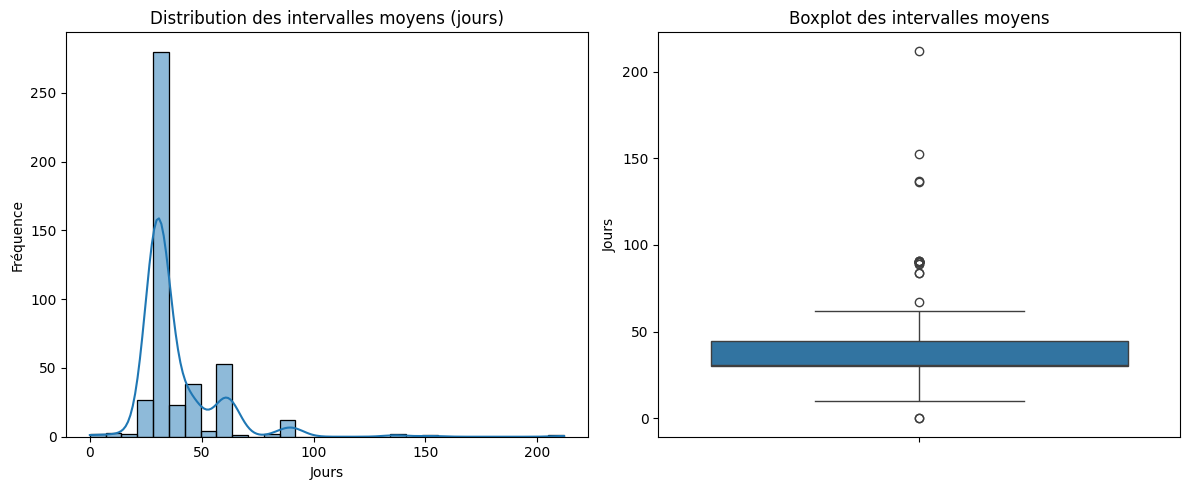

In [55]:
def calculer_temps_attente_engrais(df):
    """
    Calcule les temps d'attente entre applications d'engrais
    """
    # Trier par parcelle et date
    df = df.sort_values(['Num Parcelle', 'Campagne', 'Libelle Site', 'Date'])

    # Calculer l'intervalle depuis la dernière application
    df['jours_depuis_derniere_app'] = df.groupby(
        ['Num Parcelle', 'Campagne', 'Libelle Site']
    )['Date'].diff().dt.days

    # Calculer l'intervalle jusqu'à la prochaine application
    df['jours_jusqua_prochaine_app'] = df.groupby(
        ['Num Parcelle', 'Campagne', 'Libelle Site']
    )['Date'].diff(-1).dt.days.abs()

    # Statistiques par parcelle
    stats_parcelle = df.groupby(['Num Parcelle', 'Campagne', 'Libelle Site']).agg({
        'jours_depuis_derniere_app': ['mean', 'median', 'min', 'max', 'std'],
        'jours_jusqua_prochaine_app': ['mean', 'median', 'min', 'max'],
        'Date': ['count', 'min', 'max']
    }).round(2)

    # Aplatir les colonnes
    stats_parcelle.columns = ['_'.join(col).strip() for col in stats_parcelle.columns.values]
    stats_parcelle = stats_parcelle.reset_index()

    # Renommer pour clarté
    stats_parcelle = stats_parcelle.rename(columns={
        'jours_depuis_derniere_app_mean': 'intervalle_moyen_jours',
        'jours_depuis_derniere_app_median': 'intervalle_median_jours',
        'jours_depuis_derniere_app_std': 'intervalle_std_jours',
        'Date_count': 'nombre_applications',
        'Date_min': 'premiere_application',
        'Date_max': 'derniere_application'
    })

    # Ajouter la durée totale de fertilisation
    stats_parcelle['duree_fertilisation_jours'] = (
        pd.to_datetime(stats_parcelle['derniere_application']) -
        pd.to_datetime(stats_parcelle['premiere_application'])
    ).dt.days

    # Calculer la fréquence (applications par mois)
    stats_parcelle['frequence_mensuelle'] = (
        stats_parcelle['nombre_applications'] /
        (stats_parcelle['duree_fertilisation_jours'] / 30 + 1e-10)
    )

    return df, stats_parcelle

# Utilisation
train_base, stats_train = calculer_temps_attente_engrais(train_base)
test_base, stats_test = calculer_temps_attente_engrais(test_base)

# Afficher les statistiques
print("Statistiques des temps d'attente entre applications d'engrais:")
print(stats_train.head())

# Visualiser la distribution des intervalles moyens
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(stats_train['intervalle_moyen_jours'].dropna(), bins=30, kde=True)
plt.title('Distribution des intervalles moyens (jours)')
plt.xlabel('Jours')
plt.ylabel('Fréquence')

plt.subplot(1, 2, 2)
sns.boxplot(y=stats_train['intervalle_moyen_jours'])
plt.title('Boxplot des intervalles moyens')
plt.ylabel('Jours')

plt.tight_layout()
plt.show()

# Corrélation entre intervalle et rendement (si vous avez une variable cible)
if 'Rendement' in train_base.columns:
    correlation_data = stats_train.merge(
        train_base[['Num Parcelle', 'Campagne', 'Libelle Site', 'Rendement']].drop_duplicates(),
        on=['Num Parcelle', 'Campagne', 'Libelle Site'],
        how='left'
    )

    print("\nCorrélations avec le rendement:")
    correlations = correlation_data.corr()['Rendement'].sort_values(ascending=False)
    print(correlations.head(10))

In [56]:
# Fusionner les statistiques avec vos bases originales
train_base = train_base.merge(
    stats_train,
    on=['Num Parcelle', 'Campagne', 'Libelle Site'],
    how='left'
)

test_base = test_base.merge(
    stats_test,
    on=['Num Parcelle', 'Campagne', 'Libelle Site'],
    how='left'
)

# Vérifier les dimensions finales
print(f"Dimensions finales train_base: {train_base.shape}")
print(f"Dimensions finales test_base: {test_base.shape}")

# Liste des nouvelles features temporelles créées
features_temps = [
    'jours_depuis_derniere_app',
    'jours_jusqua_prochaine_app',
    'intervalle_moyen_jours',
    'intervalle_median_jours',
    'intervalle_std_jours',
    'nombre_applications',
    'duree_fertilisation_jours',
    'frequence_mensuelle'
]

print(f"\nNouvelles features temporelles ajoutées: {features_temps}")

Dimensions finales train_base: (1661, 56)
Dimensions finales test_base: (411, 56)

Nouvelles features temporelles ajoutées: ['jours_depuis_derniere_app', 'jours_jusqua_prochaine_app', 'intervalle_moyen_jours', 'intervalle_median_jours', 'intervalle_std_jours', 'nombre_applications', 'duree_fertilisation_jours', 'frequence_mensuelle']


In [57]:
import numpy as np
import pandas as pd

DROP_COLS = [
    "id",
    "CodeTracabilite",
    "Campagne",
    "Date",
    "Num Parcelle",
    "CodeTracabilite_x",
    "Code Ferme_y",
    "Libelle Site_y",
    "CodeTracabilite_y",
    "Surface_sum",
    "engrais_jour_annee"  # Pour suppression
]

# Fonction pour vérifier et créer une colonne si elle n'existe pas
def safe_get(df, col, default_value=0):
    if col in df.columns:
        return df[col]
    else:
        print(f"⚠️ Colonne '{col}' non trouvée, utilisation de valeur par défaut: {default_value}")
        return pd.Series(default_value, index=df.index)

# FEATURE : Saisonnalité cyclique des engrais
print("\n🔄 Ajout des features saisonnières des engrais...")

def ajouter_saisonnalite_engrais(df):
    """
    Ajoute la saisonnalité cyclique (sinus/cosinus) de la date d'engrais
    """
    df_temp = df.copy()

    # Vérifier si on a la colonne Date
    if 'Date' in df_temp.columns:
        # Convertir Date en datetime
        df_temp['Date'] = pd.to_datetime(df_temp['Date'], errors='coerce')

        # Extraire le jour de l'année
        df_temp['engrais_jour_annee'] = df_temp['Date'].dt.dayofyear

        # Calculer les features cycliques pour la saisonnalité
        df_temp['engrais_saison_sin'] = np.sin(2 * np.pi * df_temp['engrais_jour_annee'] / 365.25)
        df_temp['engrais_saison_cos'] = np.cos(2 * np.pi * df_temp['engrais_jour_annee'] / 365.25)

        print("✅ Saisonnalité cyclique d'engrais ajoutée")
    else:
        print("⚠️ Colonne 'Date' non trouvée pour la saisonnalité d'engrais")
        df_temp['engrais_jour_annee'] = 0
        df_temp['engrais_saison_sin'] = 0
        df_temp['engrais_saison_cos'] = 0

    return df_temp

# Appliquer la saisonnalité cyclique
X = ajouter_saisonnalite_engrais(X)
X_test = ajouter_saisonnalite_engrais(X_test)

# Calcul des autres features (existantes)
X['npk_sum'] = safe_get(X, 'N', 0) + safe_get(X, 'P', 0) + safe_get(X, 'K', 0)
X_test['npk_sum'] = safe_get(X_test, 'N', 0) + safe_get(X_test, 'P', 0) + safe_get(X_test, 'K', 0)

# Fertilizer per day
X['fertilizer_per_day'] = X['npk_sum'] / (safe_get(X, 'days_since_plant', 1) + 1)
X_test['fertilizer_per_day'] = X_test['npk_sum'] / (safe_get(X_test, 'days_since_plant', 1) + 1)

# Irrigation per hectare
X['irrigation_per_ha'] = safe_get(X, 'Irrigation_total_m3', 0) / (safe_get(X, 'Surface', 1) + 1e-6)
X_test['irrigation_per_ha'] = safe_get(X_test, 'Irrigation_total_m3', 0) / (safe_get(X_test, 'Surface', 1) + 1e-6)

# Phosphore per hectare
X['P_per_ha'] = safe_get(X, 'P', 0) / (safe_get(X, 'Surface', 1) + 1e-6)
X_test['P_per_ha'] = safe_get(X_test, 'P', 0) / (safe_get(X_test, 'Surface', 1) + 1e-6)

# Rainy days
if 'Pluviométrie(mm)' in X.columns:
    X['rainy_days_7d'] = X['Pluviométrie(mm)'].rolling(window=7, min_periods=1).apply(lambda x: (x > 1).sum(), raw=True).fillna(0)
    X_test['rainy_days_7d'] = X_test['Pluviométrie(mm)'].rolling(window=7, min_periods=1).apply(lambda x: (x > 1).sum(), raw=True).fillna(0)
else:
    X['rainy_days_7d'] = 0
    X_test['rainy_days_7d'] = 0
    print("⚠️ Colonne 'Pluviométrie(mm)' non trouvée pour rainy_days_7d")

# Water total
X['water_total_mm'] = safe_get(X, 'Pluviométrie(mm)', 0) + safe_get(X, 'Irrigation_total_m3', 0)
X_test['water_total_mm'] = safe_get(X_test, 'Pluviométrie(mm)', 0) + safe_get(X_test, 'Irrigation_total_m3', 0)

# Water per real hectare
if 'Surface_total' in X.columns and 'water_total_mm' in X.columns:
    X['water_per_real_ha'] = X['water_total_mm'] / X['Surface_total']
    X_test['water_per_real_ha'] = X_test['water_total_mm'] / X_test['Surface_total']
else:
    X['water_per_real_ha'] = 0
    X_test['water_per_real_ha'] = 0
    print("⚠️ Colonne 'Surface_total' ou 'water_total_mm' non trouvée pour water_per_real_ha")

# Surface ratio
if 'Surface_total' in X.columns and 'Surface_sum' in X.columns:
    X['Surface_ratio'] = X['Surface_total'] / X['Surface_sum']
    X_test['Surface_ratio'] = X_test['Surface_total'] / X_test['Surface_sum']
else:
    X['Surface_ratio'] = 0
    X_test['Surface_ratio'] = 0
    print("⚠️ Colonne 'Surface_total' ou 'Surface_sum' non trouvée pour Surface_ratio")

# Thermal amplitude
if 'TemperatureMax C°' in X.columns and 'TemperatureMin C°' in X.columns:
    X["thermal_amplitude"] = X["TemperatureMax C°"] - X["TemperatureMin C°"]
    X_test["thermal_amplitude"] = X_test["TemperatureMax C°"] - X_test["TemperatureMin C°"]
else:
    X["thermal_amplitude"] = 0
    X_test["thermal_amplitude"] = 0
    print("⚠️ Colonnes de température non trouvées pour thermal_amplitude")

# Clip surfaces extrêmes
for col in ["Surface", "Sup Debut Camp", "Sup Fin Camp"]:
    if col in X.columns:
        q99 = X[col].quantile(0.98)
        X[col] = X[col].clip(upper=q99)
        if col in X_test.columns:
            X_test[col] = X_test[col].clip(upper=q99)
    else:
        print(f"⚠️ Colonne {col} non trouvée pour clipping")

# log versions
if 'irrigation_per_ha' in X.columns:
    X["log_irrigation_per_ha"] = np.log1p(X["irrigation_per_ha"])
    X_test["log_irrigation_per_ha"] = np.log1p(X_test["irrigation_per_ha"])
else:
    X["log_irrigation_per_ha"] = 0
    X_test["log_irrigation_per_ha"] = 0

# Suppression des colonnes avec vérification
cols_to_drop_x = [c for c in DROP_COLS if c in X.columns]
if cols_to_drop_x:
    X = X.drop(columns=cols_to_drop_x)
    print(f"✅ Colonnes supprimées de X: {cols_to_drop_x}")

cols_to_drop_test = [c for c in DROP_COLS if c in X_test.columns]
if cols_to_drop_test:
    X_test = X_test.drop(columns=cols_to_drop_test)
    print(f"✅ Colonnes supprimées de X_test: {cols_to_drop_test}")

print(f"\n✅ Prétraitement terminé!")
print(f"   Shape de X: {X.shape}")
print(f"   Shape de X_test: {X_test.shape}")
print(f"\n✅ Features saisonnières ajoutées:")
print(f"   - engrais_saison_sin: Sinus du jour de l'année")
print(f"   - engrais_saison_cos: Cosinus du jour de l'année")
print(f"   (Colonne intermédiaire 'engrais_jour_annee' supprimée)")

# Vérification rapide des nouvelles features
if 'engrais_saison_sin' in X.columns and 'engrais_saison_cos' in X.columns:
    print(f"\n📊 Statistiques des features saisonnières:")
    print(f"   engrais_saison_sin - Min: {X['engrais_saison_sin'].min():.3f}, Max: {X['engrais_saison_sin'].max():.3f}")
    print(f"   engrais_saison_cos - Min: {X['engrais_saison_cos'].min():.3f}, Max: {X['engrais_saison_cos'].max():.3f}")


🔄 Ajout des features saisonnières des engrais...
✅ Saisonnalité cyclique d'engrais ajoutée
✅ Saisonnalité cyclique d'engrais ajoutée
✅ Colonnes supprimées de X: ['id', 'CodeTracabilite', 'Campagne', 'Date', 'Num Parcelle', 'Surface_sum', 'engrais_jour_annee']
✅ Colonnes supprimées de X_test: ['id', 'CodeTracabilite', 'Campagne', 'Date', 'Num Parcelle', 'Surface_sum', 'engrais_jour_annee']

✅ Prétraitement terminé!
   Shape de X: (1674, 43)
   Shape de X_test: (411, 43)

✅ Features saisonnières ajoutées:
   - engrais_saison_sin: Sinus du jour de l'année
   - engrais_saison_cos: Cosinus du jour de l'année
   (Colonne intermédiaire 'engrais_jour_annee' supprimée)

📊 Statistiques des features saisonnières:
   engrais_saison_sin - Min: -1.000, Max: 1.000
   engrais_saison_cos - Min: -1.000, Max: 1.000


In [58]:
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
num_cols = X.select_dtypes(exclude=["object"]).columns.tolist()

print("Catégorielles :", cat_cols)
print("Numériques :", num_cols)


Catégorielles : ['Libelle Site', 'Porte Greffe', 'Region', 'Code Ferme', 'Libelle Variete']
Numériques : ['Date Plantation', 'Date Arrachage', 'Sup Debut Camp', 'Sup Plantee', 'Sup Arrachee', 'Sup Fin Camp', 'Surface', 'Surface_total', 'days_since_plant', 'days_to_arrachage', 'OrdreMois', 'dayofyear', 'N', 'P', 'K', 'Irrigation_total_m3', 'Irrigation_moyenne_m3', 'Irrigation_nb', 'TemperatureMax C°', 'TemperatureMin C°', 'TemperatureMoy C°', 'HumiditeRelativeMoy %', 'HumiditeRelativeMin %', 'HumiditeRelativeMax %', 'ET0(mm)', 'Pluviométrie(mm)', 'engrais_saison_sin', 'engrais_saison_cos', 'npk_sum', 'fertilizer_per_day', 'irrigation_per_ha', 'P_per_ha', 'rainy_days_7d', 'water_total_mm', 'water_per_real_ha', 'Surface_ratio', 'thermal_amplitude', 'log_irrigation_per_ha']


In [59]:
to_drop = [
    "Sup Plantee"
    "Sup Debut Camp",
    "Code Ferme"

]

X.drop(columns=to_drop, inplace=True, errors="ignore")
X_test.drop(columns=to_drop, inplace=True, errors="ignore")

In [60]:
# ======================================================================
# NETTOYAGE DES DONNÉES SELON LE GUIDE BEEONE (VERSION CORRIGÉE)
# ======================================================================
print("🧹 NETTOYAGE DES DONNÉES (GUIDE BEEONE - VERSION ADAPTÉE)")
print("="*80)

# Créer des copies pour éviter les warnings
X_clean = X.copy()
X_test_clean = X_test.copy()

# ======================================================================
# 1. LOGIQUE DE SÉLECTION DE LA SUPERFICIE
# ======================================================================
print("\n1️⃣  APPLICATION DE LA LOGIQUE DE SURFACE...")

# Vérifier que les colonnes nécessaires existent
if all(col in X_clean.columns for col in ['Sup Fin Camp', 'Sup Debut Camp']):
    # Appliquer la logique: Si Sup Fin Camp > 0 → Sup Fin Camp, sinon Sup Debut Camp
    X_clean['Surface'] = np.where(
        X_clean['Sup Fin Camp'] > 0,
        X_clean['Sup Fin Camp'],
        X_clean['Sup Debut Camp']
    )

    X_test_clean['Surface'] = np.where(
        X_test_clean['Sup Fin Camp'] > 0,
        X_test_clean['Sup Fin Camp'],
        X_test_clean['Sup Debut Camp']
    )

    print(f"  ✅ Logique de surface appliquée")
    print(f"     Sup Fin Camp > 0: {(X_clean['Sup Fin Camp'] > 0).sum()} parcelles")
    print(f"     Utilisation Sup Debut Camp: {(X_clean['Sup Fin Camp'] <= 0).sum()} parcelles")

    # Mettre à jour Surface_total si elle existe
    if 'Surface_total' in X_clean.columns:
        X_clean['Surface_total'] = X_clean[['Sup Debut Camp', 'Sup Plantee']].sum(axis=1)
        X_test_clean['Surface_total'] = X_test_clean[['Sup Debut Camp', 'Sup Plantee']].sum(axis=1)
else:
    print(f"  ⚠️  Colonnes de surface manquantes")

# ======================================================================
# 2. CORRECTION DES VALEURS NÉGATIVES
# ======================================================================
print("\n2️⃣  CORRECTION DES VALEURS NÉGATIVES...")

# Liste des colonnes qui ne devraient pas être négatives
non_negative_cols = ['N', 'P', 'K', 'Irrigation_total_m3', 'Irrigation_moyenne_m3',
                     'Irrigation_nb', 'Pluviométrie(mm)', 'npk_sum', 'fertilizer_per_day',
                     'irrigation_per_ha', 'P_per_ha', 'water_total_mm', 'water_per_real_ha']

for col in non_negative_cols:
    if col in X_clean.columns:
        # Compter les valeurs négatives avant correction
        neg_count_train = (X_clean[col] < 0).sum()
        neg_count_test = (X_test_clean[col] < 0).sum() if col in X_test_clean.columns else 0

        # Corriger dans train
        if neg_count_train > 0:
            X_clean.loc[X_clean[col] < 0, col] = 0
            print(f"  ✅ {col} (train): {neg_count_train} valeurs négatives corrigées")

        # Corriger dans test
        if neg_count_test > 0:
            X_test_clean.loc[X_test_clean[col] < 0, col] = 0
            print(f"  ✅ {col} (test): {neg_count_test} valeurs négatives corrigées")

# ======================================================================
# 3. ANALYSE DES PARCELLES ARRACHÉES
# ======================================================================
print("\n3️⃣  ANALYSE DES PARCELLES ARRACHÉES...")

if all(col in X_clean.columns for col in ['Sup Fin Camp', 'Sup Debut Camp']):
    # Identifier les parcelles arrachées (Sup Fin Camp = 0 mais Sup Debut Camp > 0)
    parcelles_arrachees_mask = (X_clean['Sup Fin Camp'] == 0) & (X_clean['Sup Debut Camp'] > 0)
    parcelles_arrachees = X_clean[parcelles_arrachees_mask]

    print(f"  ✅ {len(parcelles_arrachees)} parcelles arrachées identifiées")

    # Afficher un échantillon avec les colonnes disponibles
    if len(parcelles_arrachees) > 0:
        print(f"  Échantillon (3 premières):")
        # Colonnes disponibles pour affichage
        available_cols = []
        for col in ['Sup Debut Camp', 'Sup Fin Camp', 'Surface']:
            if col in parcelles_arrachees.columns:
                available_cols.append(col)

        # Ajouter d'autres colonnes intéressantes si disponibles
        optional_cols = ['days_since_plant', 'days_to_arrachage', 'N', 'P', 'K']
        for col in optional_cols:
            if col in parcelles_arrachees.columns:
                available_cols.append(col)

        if available_cols:
            print(parcelles_arrachees[available_cols].head(3).to_string())
else:
    print(f"  ℹ️  Colonnes de surface manquantes pour l'analyse")

# ======================================================================
# 4. VÉRIFICATION DES VALEURS ABERRANTES
# ======================================================================
print("\n4️⃣  VÉRIFICATION DES VALEURS ABERRANTES...")

# Vérifier les valeurs extrêmes pour certaines colonnes clés
check_cols = [
    ('days_since_plant', 0, 365),  # Maximum réaliste: 1 an
    ('days_to_arrachage', 0, 365),
    ('TemperatureMax C°', 15, 45),
    ('TemperatureMin C°', 0, 25),
    ('TemperatureMoy C°', 10, 35),
    ('HumiditeRelativeMoy %', 0, 100),
    ('HumiditeRelativeMin %', 0, 100),
    ('HumiditeRelativeMax %', 0, 100)
]

for col, min_val, max_val in check_cols:
    if col in X_clean.columns:
        # Détecter les valeurs aberrantes
        outliers_low = (X_clean[col] < min_val).sum()
        outliers_high = (X_clean[col] > max_val).sum()

        if outliers_low > 0 or outliers_high > 0:
            print(f"  ⚠️  {col}: {outliers_low + outliers_high} valeurs en dehors de [{min_val}, {max_val}]")

            # Corriger les valeurs aberrantes
            X_clean[col] = X_clean[col].clip(min_val, max_val)
            if col in X_test_clean.columns:
                X_test_clean[col] = X_test_clean[col].clip(min_val, max_val)

            print(f"     ✅ Valeurs corrigées par clipping")

# ======================================================================
# 5. VÉRIFICATION DES COHÉRENCES LOGIQUES
# ======================================================================
print("\n5️⃣  VÉRIFICATION DES COHÉRENCES LOGIQUES...")

# 1. Vérifier que TemperatureMin <= TemperatureMoy <= TemperatureMax
if all(col in X_clean.columns for col in ['TemperatureMin C°', 'TemperatureMoy C°', 'TemperatureMax C°']):
    incoherent_temp = ((X_clean['TemperatureMin C°'] > X_clean['TemperatureMoy C°']) |
                      (X_clean['TemperatureMoy C°'] > X_clean['TemperatureMax C°'])).sum()

    if incoherent_temp > 0:
        print(f"  ⚠️  {incoherent_temp} incohérences de température détectées")
        # Corriger en recalculant TemperatureMoy comme moyenne de Min et Max
        X_clean['TemperatureMoy C°'] = (X_clean['TemperatureMin C°'] + X_clean['TemperatureMax C°']) / 2
        print(f"     ✅ Températures recalculées")

# 2. Vérifier que HumiditeRelativeMin <= HumiditeRelativeMoy <= HumiditeRelativeMax
if all(col in X_clean.columns for col in ['HumiditeRelativeMin %', 'HumiditeRelativeMoy %', 'HumiditeRelativeMax %']):
    incoherent_hum = ((X_clean['HumiditeRelativeMin %'] > X_clean['HumiditeRelativeMoy %']) |
                     (X_clean['HumiditeRelativeMoy %'] > X_clean['HumiditeRelativeMax %'])).sum()

    if incoherent_hum > 0:
        print(f"  ⚠️  {incoherent_hum} incohérences d'humidité détectées")
        # Corriger en recalculant HumiditeRelativeMoy comme moyenne de Min et Max
        X_clean['HumiditeRelativeMoy %'] = (X_clean['HumiditeRelativeMin %'] + X_clean['HumiditeRelativeMax %']) / 2
        print(f"     ✅ Humidités recalculées")

# 3. Vérifier thermal_amplitude = TemperatureMax - TemperatureMin
if all(col in X_clean.columns for col in ['TemperatureMax C°', 'TemperatureMin C°', 'thermal_amplitude']):
    # Calculer la vraie amplitude
    true_amplitude = X_clean['TemperatureMax C°'] - X_clean['TemperatureMin C°']

    # Comparer avec la colonne existante
    diff = abs(X_clean['thermal_amplitude'] - true_amplitude).mean()

    if diff > 0.1:  # Si différence moyenne > 0.1°C
        print(f"  ⚠️  Écart dans thermal_amplitude: moyenne de {diff:.2f}°C")
        X_clean['thermal_amplitude'] = true_amplitude
        print(f"     ✅ thermal_amplitude recalculée")

# ======================================================================
# 6. VÉRIFICATION FINALE
# ======================================================================
print("\n6️⃣  VÉRIFICATION FINALE DES DONNÉES...")

print(f"  Dimensions finales:")
print(f"    X: {X_clean.shape} (train)")
print(f"    X_test: {X_test_clean.shape} (test)")

print(f"\n  Valeurs manquantes:")
print(f"    X: {X_clean.isna().sum().sum()} valeurs NaN")
print(f"    X_test: {X_test_clean.isna().sum().sum()} valeurs NaN")

# Vérifier la qualité des données nettoyées
print(f"\n  Statistiques clés après nettoyage:")
key_cols = ['Surface', 'days_since_plant', 'TemperatureMax C°', 'HumiditeRelativeMoy %', 'Irrigation_total_m3']
for col in key_cols:
    if col in X_clean.columns:
        min_val = X_clean[col].min()
        max_val = X_clean[col].max()
        mean_val = X_clean[col].mean()
        print(f"    {col}: {min_val:.2f} à {max_val:.2f} (moyenne: {mean_val:.2f})")

# ======================================================================
# 7. SAUVEGARDE ET EXPORT
# ======================================================================
print("\n" + "="*80)
print("💾 SAUVEGARDE DES DONNÉES NETTOYÉES")
print("="*80)

# Remplacer les DataFrames originaux
X = X_clean.copy()
X_test = X_test_clean.copy()

print(f"✅ Données nettoyées avec succès!")
print(f"\n📊 RÉSUMÉ DES ACTIONS:")
print(f"  1. Logique de surface appliquée (Fin > 0 ? Fin : Debut)")
print(f"  2. Valeurs négatives corrigées pour N, P, K, irrigation, etc.")
print(f"  3. {len(parcelles_arrachees)} parcelles arrachées identifiées")
print(f"  4. Valeurs aberrantes détectées et corrigées")
print(f"  5. Cohérences logiques vérifiées (température, humidité)")
print(f"  6. Données finales: {X.shape[0]} observations, {X.shape[1]} features")

print(f"\n🚀 Les données sont maintenant prêtes pour l'entraînement!")

🧹 NETTOYAGE DES DONNÉES (GUIDE BEEONE - VERSION ADAPTÉE)

1️⃣  APPLICATION DE LA LOGIQUE DE SURFACE...
  ✅ Logique de surface appliquée
     Sup Fin Camp > 0: 1488 parcelles
     Utilisation Sup Debut Camp: 137 parcelles

2️⃣  CORRECTION DES VALEURS NÉGATIVES...

3️⃣  ANALYSE DES PARCELLES ARRACHÉES...
  ✅ 137 parcelles arrachées identifiées
  Échantillon (3 premières):
    Sup Debut Camp  Sup Fin Camp  Surface  days_since_plant  days_to_arrachage          N         P         K
18         10.2572           0.0  10.2572           14245.0               30.0        NaN       NaN       NaN
25          4.0326           0.0   4.0326           13790.0              120.0   4.838932  1.284933  1.955987
26          4.0326           0.0   4.0326           13821.0               89.0  10.394838  2.929438  4.055007

4️⃣  VÉRIFICATION DES VALEURS ABERRANTES...
  ⚠️  days_since_plant: 1621 valeurs en dehors de [0, 365]
     ✅ Valeurs corrigées par clipping
  ⚠️  days_to_arrachage: 1465 valeurs en deho

In [61]:
!pip install category_encoders -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.9/107.9 kB 4.2 MB/s eta 0:00:00


In [62]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

# ======================================================================
# 1. NETTOYAGE AVEC CORRÉLATION TEMPÉRATURE-HUMIDITÉ
# ======================================================================
print("🧹 NETTOYAGE AVEC MODÈLE DE PRÉDICTION TEMPÉRATURE-HUMIDITÉ")

# Créer une copie pour éviter les warnings
X_clean = X.copy()
X_test_clean = X_test.copy()

# Colonnes de température et d'humidité
temp_cols = ['TemperatureMax C°', 'TemperatureMin C°', 'TemperatureMoy C°']
humidity_cols = ['HumiditeRelativeMoy %', 'HumiditeRelativeMin %', 'HumiditeRelativeMax %']

# Vérifier quelles colonnes existent réellement
temp_cols_exist = [col for col in temp_cols if col in X_clean.columns]
humidity_cols_exist = [col for col in humidity_cols if col in X_clean.columns]

print(f"Colonnes température trouvées: {temp_cols_exist}")
print(f"Colonnes humidité trouvées: {humidity_cols_exist}")

# ÉTAPE 1: PRÉDIRE LES TEMPÉRATURES MANQUANTES AVEC L'HUMIDITÉ
print("\n1️⃣  Prédiction des températures manquantes...")

for temp_col in temp_cols_exist:
    # Données d'entraînement (où température ET humidité sont connues)
    train_mask = X_clean[temp_col].notna() & X_clean[humidity_cols_exist].notna().all(axis=1)

    if train_mask.sum() > 10:  # Besoin d'au moins 10 points pour entraîner
        # Entraîner un modèle de régression
        model = LinearRegression()
        model.fit(X_clean.loc[train_mask, humidity_cols_exist],
                 X_clean.loc[train_mask, temp_col])

        # Prédire pour les données manquantes dans X
        missing_mask_X = X_clean[temp_col].isna() & X_clean[humidity_cols_exist].notna().all(axis=1)
        if missing_mask_X.any():
            X_clean.loc[missing_mask_X, temp_col] = model.predict(
                X_clean.loc[missing_mask_X, humidity_cols_exist]
            )
            print(f"  ✅ {temp_col} (X): {missing_mask_X.sum()} valeurs prédites")

        # Prédire pour les données manquantes dans X_test
        if temp_col in X_test_clean.columns:
            missing_mask_test = X_test_clean[temp_col].isna() & X_test_clean[humidity_cols_exist].notna().all(axis=1)
            if missing_mask_test.any():
                X_test_clean.loc[missing_mask_test, temp_col] = model.predict(
                    X_test_clean.loc[missing_mask_test, humidity_cols_exist]
                )
                print(f"  ✅ {temp_col} (X_test): {missing_mask_test.sum()} valeurs prédites")

# ÉTAPE 2: NETTOYAGE DES AUTRES VARIABLES
print("\n2️⃣  Nettoyage des autres variables...")

# Liste des colonnes catégorielles (À ADAPTER)
cat_cols = ['Libelle Site', 'Porte Greffe', 'Region', 'Code Ferme', 'Libelle Variete']

# A. Températures restantes (si toujours NaN après prédiction)
for temp_col in temp_cols_exist:
    # Remplacer les NaN restants par la moyenne de la région
    if 'Region' in X_clean.columns:
        X_clean[temp_col] = X_clean.groupby('Region')[temp_col].transform(
            lambda x: x.fillna(x.mean())
        )
        X_test_clean[temp_col] = X_test_clean.groupby('Region')[temp_col].transform(
            lambda x: x.fillna(x.mean())
        )
    else:
        # Moyenne globale si pas de région
        global_mean = X_clean[temp_col].mean()
        X_clean[temp_col].fillna(global_mean, inplace=True)
        X_test_clean[temp_col].fillna(global_mean, inplace=True)

# B. Autres variables numériques
numeric_cols = X_clean.select_dtypes(include=[np.number]).columns
other_numeric = [col for col in numeric_cols if col not in temp_cols_exist]

for col in other_numeric:
    if col in X_clean.columns:
        # Imputer par la médiane de la région
        if 'Region' in X_clean.columns:
            X_clean[col] = X_clean.groupby('Region')[col].transform(
                lambda x: x.fillna(x.median())
            )
            if col in X_test_clean.columns:
                X_test_clean[col] = X_test_clean.groupby('Region')[col].transform(
                    lambda x: x.fillna(x.median())
                )
        else:
            # Médiane globale
            global_median = X_clean[col].median()
            X_clean[col].fillna(global_median, inplace=True)
            if col in X_test_clean.columns:
                X_test_clean[col].fillna(global_median, inplace=True)

# C. Variables catégorielles
for col in cat_cols:
    if col in X_clean.columns:
        # Convertir en string d'abord
        X_clean[col] = X_clean[col].astype(str)
        X_test_clean[col] = X_test_clean[col].astype(str)

        # Remplacer NaN par la valeur la plus fréquente
        mode_val = X_clean[col].mode()[0] if not X_clean[col].mode().empty else 'MISSING'
        X_clean[col].replace('nan', mode_val, inplace=True)
        X_clean[col].fillna(mode_val, inplace=True)

        if col in X_test_clean.columns:
            X_test_clean[col].replace('nan', mode_val, inplace=True)
            X_test_clean[col].fillna(mode_val, inplace=True)

# D. Remplir les NaN restants
X_clean.fillna(X_clean.median(numeric_only=True), inplace=True)
X_test_clean.fillna(X_clean.median(numeric_only=True), inplace=True)

print(f"\n✅ Nettoyage terminé:")
print(f"   X: {X.isna().sum().sum()} NaN → {X_clean.isna().sum().sum()} NaN")
print(f"   X_test: {X_test.isna().sum().sum()} NaN → {X_test_clean.isna().sum().sum()} NaN")

# Remplacer les DataFrames originaux
X = X_clean
X_test = X_test_clean

🧹 NETTOYAGE AVEC MODÈLE DE PRÉDICTION TEMPÉRATURE-HUMIDITÉ
Colonnes température trouvées: ['TemperatureMax C°', 'TemperatureMin C°', 'TemperatureMoy C°']
Colonnes humidité trouvées: ['HumiditeRelativeMoy %', 'HumiditeRelativeMin %', 'HumiditeRelativeMax %']

1️⃣  Prédiction des températures manquantes...

2️⃣  Nettoyage des autres variables...

✅ Nettoyage terminé:
   X: 9096 NaN → 104 NaN
   X_test: 2090 NaN → 25 NaN


/tmp/ipykernel_3449/3878260213.py:108: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  X_clean[col].replace('nan', mode_val, inplace=True)
/tmp/ipykernel_3449/3878260213.py:109: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)

In [63]:
import pandas as pd

# VÉRIFICATION DÉTAILLÉE AVEC VISUALISATION
def check_temperature_nan(X, X_test=None):
    """Vérifie les valeurs manquantes dans les températures"""

    temp_cols = ['TemperatureMax C°', 'TemperatureMin C°', 'TemperatureMoy C°']

    print("📋 RÉSUMÉ DES TEMPÉRATURES MANQUANTES")
    print("-"*50)

    # Créer un DataFrame pour la visualisation
    results = []
    for col in temp_cols:
        if col in X.columns:
            train_nan = X[col].isna().sum()
            train_total = len(X[col])
            train_pct = (train_nan / train_total) * 100

            if X_test is not None and col in X_test.columns:
                test_nan = X_test[col].isna().sum()
                test_total = len(X_test[col])
                test_pct = (test_nan / test_total) * 100
            else:
                test_nan = test_total = test_pct = None

            results.append({
                'Colonne': col,
                'Train_NaN': train_nan,
                'Train_Total': train_total,
                'Train_%': train_pct,
                'Test_NaN': test_nan,
                'Test_%': test_pct
            })

    # Afficher les résultats
    df_results = pd.DataFrame(results)
    print(df_results.to_string())

    # Afficher un message d'alerte si nécessaire
    total_train_nan = df_results['Train_NaN'].sum()
    if total_train_nan > 0:
        print(f"\n⚠️  ALERTE: {total_train_nan} valeurs manquantes au total!")
        print("\nLignes avec NaN (5 premières):")
        nan_rows = X[temp_cols].isna().any(axis=1)
        print(X.loc[nan_rows, temp_cols].head())
    else:
        print("\n✅ Toutes les températures sont complètes!")

    return df_results

# Utilisation
results_df = check_temperature_nan(X, X_test)

📋 RÉSUMÉ DES TEMPÉRATURES MANQUANTES
--------------------------------------------------
             Colonne  Train_NaN  Train_Total  Train_%  Test_NaN  Test_%
0  TemperatureMax C°          0         1674      0.0         0     0.0
1  TemperatureMin C°          0         1674      0.0         0     0.0
2  TemperatureMoy C°          0         1674      0.0         0     0.0

✅ Toutes les températures sont complètes!


📊 VISUALISATION DES DONNÉES MANQUANTES


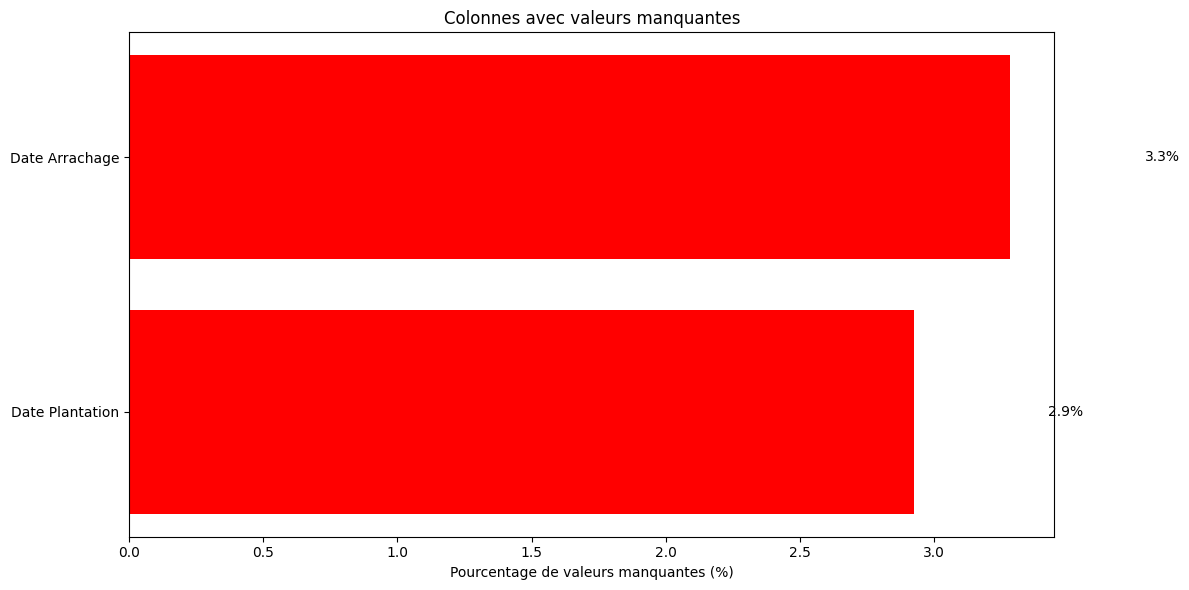


2 colonnes avec des valeurs manquantes:
  Date Arrachage: 55 valeurs (3.3%)
  Date Plantation: 49 valeurs (2.9%)


In [64]:
import matplotlib.pyplot as plt
import seaborn as sns

# VERSION AVEC VISUALISATION GRAPHIQUE
print("📊 VISUALISATION DES DONNÉES MANQUANTES")

# Calculer les pourcentages de NaN par colonne
nan_percent = (X.isna().sum() / len(X)) * 100
nan_percent = nan_percent[nan_percent > 0].sort_values(ascending=False)

if len(nan_percent) > 0:
    # Créer un graphique
    plt.figure(figsize=(12, 6))
    bars = plt.barh(nan_percent.index, nan_percent.values, color='red')
    plt.xlabel('Pourcentage de valeurs manquantes (%)')
    plt.title('Colonnes avec valeurs manquantes')
    plt.gca().invert_yaxis()  # Afficher la plus grande en haut

    # Ajouter les pourcentages sur les barres
    for bar in bars:
        width = bar.get_width()
        plt.text(width + 0.5, bar.get_y() + bar.get_height()/2,
                f'{width:.1f}%', ha='left', va='center')

    plt.tight_layout()
    plt.show()

    # Afficher les détails
    print(f"\n{len(nan_percent)} colonnes avec des valeurs manquantes:")
    for col, pct in nan_percent.items():
        count = X[col].isna().sum()
        print(f"  {col}: {count} valeurs ({pct:.1f}%)")
else:
    print("✅ Aucune colonne avec des valeurs manquantes!")

In [65]:
# VERSION AVEC STATISTIQUES DÉTAILLÉES
print("📊 STATISTIQUES DES COLONNES NUMÉRIQUES")
print("="*70)

for df_name, df in [("X", X), ("X_test", X_test)]:
    print(f"\n{df_name}:")
    numeric_cols = df.select_dtypes(include=['int64', 'float64']).columns

    for col in numeric_cols:
        min_val = df[col].min()
        max_val = df[col].max()
        mean_val = df[col].mean()
        print(f"{col:25s} Min:{min_val:8.2f} Max:{max_val:8.2f} Moy:{mean_val:8.2f}")

📊 STATISTIQUES DES COLONNES NUMÉRIQUES

X:
Sup Debut Camp            Min:    0.00 Max:   24.70 Moy:    5.50
Sup Plantee               Min:    0.00 Max:   15.36 Moy:    0.04
Sup Arrachee              Min:    0.00 Max:   28.26 Moy:    0.37
Sup Fin Camp              Min:    0.00 Max:   24.70 Moy:    5.16
Surface                   Min:    0.11 Max:   24.70 Moy:    5.54
Surface_total             Min:    0.00 Max:   24.70 Moy:    5.45
days_since_plant          Min:    0.00 Max:  365.00 Moy:  364.13
days_to_arrachage         Min:    0.00 Max:  365.00 Moy:  343.10
N                         Min:    0.00 Max: 2016.03 Moy:   82.06
P                         Min:    0.00 Max:  895.98 Moy:   35.58
K                         Min:    0.00 Max: 1214.72 Moy:   49.48
Irrigation_total_m3       Min:  568.69 Max:372582.04 Moy:56088.76
Irrigation_moyenne_m3     Min:    3.47 Max: 1420.08 Moy:  252.95
Irrigation_nb             Min:   12.00 Max:  702.00 Moy:  240.04
TemperatureMax C°         Min:   16.99 Max:   

In [66]:
# NETTOYAGE ULTRA-MINIMALISTE
print("🧹 NETTOYAGE RAPIDE")



# 2. Limiter les surfaces à minimum 0.01
surface_cols = ['Surface', 'Surface_total']
for col in surface_cols:
    X[col] = X[col].clip(lower=0.01)
    X_test[col] = X_test[col].clip(lower=0.01)

# 3. Limiter les températures à des valeurs réalistes
temp_limits = {
    'TemperatureMin C°': (0, 25),
    'TemperatureMax C°': (15, 45),
    'TemperatureMoy C°': (10, 35)
}
for col, (low, high) in temp_limits.items():
    X[col] = X[col].clip(low, high)
    X_test[col] = X_test[col].clip(low, high)

# 4. Limiter l'humidité à 0-100%
humidity_cols = ['HumiditeRelativeMoy %', 'HumiditeRelativeMin %', 'HumiditeRelativeMax %']
for col in humidity_cols:
    X[col] = X[col].clip(0, 100)
    X_test[col] = X_test[col].clip(0, 100)

# 5. Éliminer les valeurs négatives
for df in [X, X_test]:
    for col in df.select_dtypes(include=['int64', 'float64']).columns:
        df[col] = df[col].clip(lower=0)

print(f"✅ Nettoyage terminé: X={X.shape}, X_test={X_test.shape}")

🧹 NETTOYAGE RAPIDE
✅ Nettoyage terminé: X=(1674, 42), X_test=(411, 42)


In [67]:
# ======================================================================
# TRAITEMENT DES VALEURS MANQUANTES - GUIDE MÉTHODOLOGIQUE
# ======================================================================
print("🧹 TRAITEMENT DES VALEURS MANQUANTES SELON LE GUIDE")
print("="*80)

def traiter_valeurs_manquantes(df):
    """
    Traite les valeurs manquantes selon les stratégies du guide méthodologique
    """
    df_clean = df.copy()

    print(f"🔍 Diagnostic initial: {df_clean.isna().sum().sum()} valeurs manquantes")

    # ==================================================================
    # 1. APPORTS N, P, K → Remplacer par 0
    # ==================================================================
    print("\n1️⃣  Apports N, P, K → Remplacer par 0")
    npk_cols = ['N', 'P', 'K']
    for col in npk_cols:
        if col in df_clean.columns:
            avant = df_clean[col].isna().sum()
            df_clean[col] = df_clean[col].fillna(0)
            apres = df_clean[col].isna().sum()
            if avant > 0:
                print(f"   ✅ {col}: {avant} NaN → 0 (pas d'apport)")

    # ==================================================================
    # 2. VARIABLES MÉTÉO → Médiane par région (si disponible)
    # ==================================================================
    print("\n2️⃣  Variables météo → Médiane ou interpolation")

    # Liste des variables météo potentielles
    variables_meteo = [
        'TemperatureMax C°', 'TemperatureMin C°', 'TemperatureMoy C°',
        'HumiditeRelativeMoy %', 'HumiditeRelativeMin %', 'HumiditeRelativeMax %',
        'ET0(mm)', 'ETO(mm)', 'Pluviométrie(mm)', 'Pluviometrie(mm)',
        'thermal_amplitude', 'rainy_days_7d'
    ]

    # Variables météo présentes dans le dataset
    meteo_cols = [col for col in variables_meteo if col in df_clean.columns]

    if 'Region' in df_clean.columns and meteo_cols:
        # Imputation par la médiane de la région
        for col in meteo_cols:
            avant = df_clean[col].isna().sum()
            if avant > 0:
                # Médiane par région
                df_clean[col] = df_clean.groupby('Region')[col].transform(
                    lambda x: x.fillna(x.median())
                )

                # Si encore des NaN (région entière avec NaN), utiliser la médiane globale
                df_clean[col] = df_clean[col].fillna(df_clean[col].median())

                apres = df_clean[col].isna().sum()
                print(f"   ✅ {col}: {avant} NaN → médiane régionale/globale")
    elif meteo_cols:
        # Pas de colonne Region, utiliser la médiane globale
        for col in meteo_cols:
            avant = df_clean[col].isna().sum()
            if avant > 0:
                median_val = df_clean[col].median()
                df_clean[col] = df_clean[col].fillna(median_val)
                print(f"   ✅ {col}: {avant} NaN → médiane globale ({median_val:.2f})")

    # ==================================================================
    # 3. VARIABLES CATÉGORIELLES → "Inconnu"
    # ==================================================================
    print("\n3️⃣  Variables catégorielles → 'Inconnu'")

    # Colonnes catégorielles (type object)
    cat_cols = df_clean.select_dtypes(include=['object']).columns.tolist()

    for col in cat_cols:
        avant = df_clean[col].isna().sum()
        if avant > 0:
            df_clean[col] = df_clean[col].fillna('Inconnu')
            print(f"   ✅ {col}: {avant} NaN → 'Inconnu'")

    # ==================================================================
    # 4. SURFACE et PRODUCTION → NE PAS IMPUTER (garder les NaN)
    # ==================================================================
    print("\n4️⃣  Surface et Production → Ne pas imputer")

    # Chercher les colonnes liées à la surface et production
    surface_cols = [col for col in df_clean.columns if 'surface' in col.lower() or 'sup' in col.lower()]
    production_cols = [col for col in df_clean.columns if 'production' in col.lower() or 'rendement' in col.lower()]

    variables_critiques = surface_cols + production_cols

    for col in variables_critiques:
        avant = df_clean[col].isna().sum()
        if avant > 0:
            print(f"   ⚠️  {col}: {avant} NaN → À INVESTIGUER (non imputé)")
            # On ne fait rien, on garde les NaN pour investigation

    # ==================================================================
    # 5. PORTE GREFFE → Mode ou "Inconnu"
    # ==================================================================
    print("\n5️⃣  Porte Greffe → Mode ou 'Inconnu'")

    if 'Porte Greffe' in df_clean.columns:
        avant = df_clean['Porte Greffe'].isna().sum()
        if avant > 0:
            # Calculer le mode (valeur la plus fréquente)
            mode_val = df_clean['Porte Greffe'].mode()
            if not mode_val.empty:
                # Si le mode existe, l'utiliser
                df_clean['Porte Greffe'] = df_clean['Porte Greffe'].fillna(mode_val.iloc[0])
                print(f"   ✅ Porte Greffe: {avant} NaN → mode ({mode_val.iloc[0]})")
            else:
                # Sinon, utiliser "Inconnu"
                df_clean['Porte Greffe'] = df_clean['Porte Greffe'].fillna('Inconnu')
                print(f"   ✅ Porte Greffe: {avant} NaN → 'Inconnu'")

    # ==================================================================
    # 6. AUTRES VARIABLES NUMÉRIQUES → Médiane
    # ==================================================================
    print("\n6️⃣  Autres variables numériques → Médiane")

    # Colonnes numériques restantes
    numeric_cols = df_clean.select_dtypes(include=['int64', 'float64']).columns.tolist()

    # Exclure celles déjà traitées
    exclure = npk_cols + meteo_cols + variables_critiques
    numeric_a_traiter = [col for col in numeric_cols if col not in exclure]

    for col in numeric_a_traiter:
        avant = df_clean[col].isna().sum()
        if avant > 0:
            median_val = df_clean[col].median()
            df_clean[col] = df_clean[col].fillna(median_val)
            print(f"   ✅ {col}: {avant} NaN → médiane ({median_val:.2f})")

    # ==================================================================
    # VÉRIFICATION FINALE
    # ==================================================================
    print("\n" + "="*80)
    print("📊 RÉSULTAT DU TRAITEMENT")
    print("="*80)

    total_nan_apres = df_clean.isna().sum().sum()
    print(f"Valeurs manquantes restantes: {total_nan_apres}")

    if total_nan_apres > 0:
        print("\n⚠️  Valeurs manquantes restantes (variables critiques non imputées):")
        nan_cols = df_clean.columns[df_clean.isna().any()].tolist()
        for col in nan_cols:
            nan_count = df_clean[col].isna().sum()
            print(f"   {col}: {nan_count} NaN")

    return df_clean

# ======================================================================
# APPLICATION AUX DONNÉES
# ======================================================================
print("\n📊 APPLICATION SUR X (TRAIN)")
print("-"*40)

# Créer une copie pour éviter les modifications inattendues
X_clean = traiter_valeurs_manquantes(X)

print("\n\n📊 APPLICATION SUR X_test (TEST)")
print("-"*40)

# Appliquer le même traitement à X_test
# Note: On utilise les statistiques de X pour l'imputation des variables numériques
X_test_clean = X_test.copy()

# Pour conserver la cohérence, on devrait utiliser les mêmes valeurs d'imputation
# (médianes de X) pour X_test. Réécrivons la fonction pour gérer cela.
def traiter_valeurs_manquantes_test(df_train, df_test):
    """
    Traite les valeurs manquantes dans le test set en utilisant
    les statistiques du train set pour éviter le data leakage
    """
    df_test_clean = df_test.copy()

    print(f"🔍 Diagnostic initial: {df_test_clean.isna().sum().sum()} valeurs manquantes")

    # 1. NPK → 0 (comme pour le train)
    npk_cols = ['N', 'P', 'K']
    for col in npk_cols:
        if col in df_test_clean.columns:
            df_test_clean[col] = df_test_clean[col].fillna(0)

    # 2. Variables météo → Utiliser les médianes du train
    variables_meteo = [
        'TemperatureMax C°', 'TemperatureMin C°', 'TemperatureMoy C°',
        'HumiditeRelativeMoy %', 'HumiditeRelativeMin %', 'HumiditeRelativeMax %',
        'ET0(mm)', 'ETO(mm)', 'Pluviométrie(mm)', 'Pluviometrie(mm)',
        'thermal_amplitude', 'rainy_days_7d'
    ]

    meteo_cols = [col for col in variables_meteo if col in df_test_clean.columns]

    for col in meteo_cols:
        if col in df_train.columns:
            median_train = df_train[col].median()
            df_test_clean[col] = df_test_clean[col].fillna(median_train)

    # 3. Variables catégorielles → "Inconnu"
    cat_cols = df_test_clean.select_dtypes(include=['object']).columns.tolist()
    for col in cat_cols:
        df_test_clean[col] = df_test_clean[col].fillna('Inconnu')

    # 4. Surface/Production → Ne pas imputer
    # (on ne fait rien)

    # 5. Porte Greffe → Mode du train ou "Inconnu"
    if 'Porte Greffe' in df_test_clean.columns and 'Porte Greffe' in df_train.columns:
        mode_train = df_train['Porte Greffe'].mode()
        if not mode_train.empty:
            df_test_clean['Porte Greffe'] = df_test_clean['Porte Greffe'].fillna(mode_train.iloc[0])
        else:
            df_test_clean['Porte Greffe'] = df_test_clean['Porte Greffe'].fillna('Inconnu')

    # 6. Autres numériques → Médianes du train
    numeric_cols = df_test_clean.select_dtypes(include=['int64', 'float64']).columns.tolist()
    exclure = npk_cols + meteo_cols
    numeric_a_traiter = [col for col in numeric_cols if col not in exclure]

    for col in numeric_a_traiter:
        if col in df_train.columns:
            median_train = df_train[col].median()
            df_test_clean[col] = df_test_clean[col].fillna(median_train)

    total_nan_apres = df_test_clean.isna().sum().sum()
    print(f"Valeurs manquantes restantes: {total_nan_apres}")

    return df_test_clean

X_test_clean = traiter_valeurs_manquantes_test(X, X_test)

# ======================================================================
# SAUVEGARDE ET RÉSUMÉ
# ======================================================================
print("\n" + "="*80)
print("💾 SAUVEGARDE DES DONNÉES TRAITÉES")
print("="*80)

# Remplacer les DataFrames originaux
X = X_clean.copy()
X_test = X_test_clean.copy()

print(f"\n✅ TRAITEMENT TERMINÉ!")
print(f"\n📊 RÉSUMÉ:")
print(f"   X shape: {X.shape}")
print(f"   X_test shape: {X_test.shape}")
print(f"   Valeurs manquantes dans X: {X.isna().sum().sum()}")
print(f"   Valeurs manquantes dans X_test: {X_test.isna().sum().sum()}")

print(f"\n📋 STRATÉGIES APPLIQUÉES:")
strategies = [
    ("N, P, K", "0 (pas d'apport)"),
    ("Variables météo", "Médiane par région/globale"),
    ("Variables catégorielles", "'Inconnu'"),
    ("Surface/Production", "Non imputées (à investiguer)"),
    ("Porte Greffe", "Mode ou 'Inconnu'"),
    ("Autres numériques", "Médiane")
]

for variable, strategie in strategies:
    print(f"   • {variable:25s} → {strategie}")

# ======================================================================
# INVESTIGATION DES VARIABLES CRITIQUES RESTANTES
# ======================================================================
print("\n" + "="*80)
print("🔍 INVESTIGATION DES VARIABLES CRITIQUES (SURFACE/PRODUCTION)")
print("="*80)

# Chercher les colonnes avec NaN restants
nan_cols = X.columns[X.isna().any()].tolist()

if nan_cols:
    print(f"Colonnes avec valeurs manquantes restantes:")
    for col in nan_cols:
        nan_count = X[col].isna().sum()
        nan_pct = (nan_count / len(X)) * 100
        print(f"   {col}: {nan_count} NaN ({nan_pct:.1f}%)")

    print(f"\n⚠️  Ces valeurs doivent être investiguées selon le guide.")
    print(f"   Actions possibles:")
    print(f"   1. Vérifier la source des données")
    print(f"   2. Contacter les responsables des données")
    print(f"   3. Exclure les observations problématiques si nécessaire")
else:
    print("✅ Aucune valeur manquante dans les variables critiques!")

print("\n" + "="*80)
print("🚀 DONNÉES PRÊTES POUR LA MODÉLISATION")
print("="*80)

🧹 TRAITEMENT DES VALEURS MANQUANTES SELON LE GUIDE

📊 APPLICATION SUR X (TRAIN)
----------------------------------------
🔍 Diagnostic initial: 104 valeurs manquantes

1️⃣  Apports N, P, K → Remplacer par 0

2️⃣  Variables météo → Médiane ou interpolation

3️⃣  Variables catégorielles → 'Inconnu'

4️⃣  Surface et Production → Ne pas imputer

5️⃣  Porte Greffe → Mode ou 'Inconnu'

6️⃣  Autres variables numériques → Médiane

📊 RÉSULTAT DU TRAITEMENT
Valeurs manquantes restantes: 104

⚠️  Valeurs manquantes restantes (variables critiques non imputées):
   Date Plantation: 49 NaN
   Date Arrachage: 55 NaN


📊 APPLICATION SUR X_test (TEST)
----------------------------------------
🔍 Diagnostic initial: 25 valeurs manquantes
Valeurs manquantes restantes: 25

💾 SAUVEGARDE DES DONNÉES TRAITÉES

✅ TRAITEMENT TERMINÉ!

📊 RÉSUMÉ:
   X shape: (1674, 42)
   X_test shape: (411, 42)
   Valeurs manquantes dans X: 104
   Valeurs manquantes dans X_test: 25

📋 STRATÉGIES APPLIQUÉES:
   • N, P, K           

In [68]:
print(X.columns.tolist())

['Libelle Site', 'Date Plantation', 'Date Arrachage', 'Porte Greffe', 'Sup Debut Camp', 'Sup Plantee', 'Sup Arrachee', 'Sup Fin Camp', 'Surface', 'Surface_total', 'days_since_plant', 'days_to_arrachage', 'OrdreMois', 'dayofyear', 'N', 'P', 'K', 'Irrigation_total_m3', 'Irrigation_moyenne_m3', 'Irrigation_nb', 'Region', 'Libelle Variete', 'TemperatureMax C°', 'TemperatureMin C°', 'TemperatureMoy C°', 'HumiditeRelativeMoy %', 'HumiditeRelativeMin %', 'HumiditeRelativeMax %', 'ET0(mm)', 'Pluviométrie(mm)', 'engrais_saison_sin', 'engrais_saison_cos', 'npk_sum', 'fertilizer_per_day', 'irrigation_per_ha', 'P_per_ha', 'rainy_days_7d', 'water_total_mm', 'water_per_real_ha', 'Surface_ratio', 'thermal_amplitude', 'log_irrigation_per_ha']


In [69]:
# Ajoutez ceci avant la boucle KFold
print(f"Dimensions de X: {X.shape}")
print(f"Dimensions de y: {y.shape if hasattr(y, 'shape') else len(y)}")
print(f"Type de X: {type(X)}")
print(f"Type de y: {type(y)}")

# Vérifiez les indices
if isinstance(X, pd.DataFrame):
    print(f"Index de X: min={X.index.min()}, max={X.index.max()}")
if isinstance(y, (pd.Series, pd.DataFrame)):
    print(f"Index de y: min={y.index.min()}, max={y.index.max()}")

Dimensions de X: (1674, 42)
Dimensions de y: (1661,)
Type de X: <class 'pandas.core.frame.DataFrame'>
Type de y: <class 'pandas.core.series.Series'>
Index de X: min=0, max=1673
Index de y: min=0, max=1660


In [70]:
# Ajoutez ce code AVANT la configuration KFold pour aligner X et y
print(f"Dimensions avant alignement: X={X.shape}, y={y.shape}")

# Trouver les index communs
common_idx = X.index.intersection(y.index)
print(f"Nombre d'index communs: {len(common_idx)}")

# Aligner X et y
X = X.loc[common_idx].copy()
y = y.loc[common_idx].copy()

print(f"Dimensions après alignement: X={X.shape}, y={y.shape}")

Dimensions avant alignement: X=(1674, 42), y=(1661,)
Nombre d'index communs: 1661
Dimensions après alignement: X=(1661, 42), y=(1661,)


In [71]:
# Si vous voulez garder l'information des dates au lieu de les supprimer
date_cols = ['Date Plantation', 'Date Arrachage']

for col in date_cols:
    if col in X.columns:
        # Convertir en timestamp Unix (nombre de secondes)
        X[f'{col}_timestamp'] = X[col].astype('int64') // 10**9
        X_test[f'{col}_timestamp'] = X_test[col].astype('int64') // 10**9

        # Extraire des features temporelles
        X[f'{col}_year'] = X[col].dt.year
        X[f'{col}_month'] = X[col].dt.month
        X[f'{col}_day'] = X[col].dt.day
        X_test[f'{col}_year'] = X_test[col].dt.year
        X_test[f'{col}_month'] = X_test[col].dt.month
        X_test[f'{col}_day'] = X_test[col].dt.day

# Puis supprimer les colonnes datetime originales
X = X.drop(columns=date_cols)
X_test = X_test.drop(columns=date_cols)

In [72]:
X ['Libelle Variete'].unique()


array(['Variete1', 'Variete2', 'Variete9', 'Variete10', 'Variete4',
       'Variete12', 'Variete6', 'Variete13', 'Variete14', 'Variete15',
       'Variete16', 'Variete5', 'Variete17', 'Variete18', 'Variete21',
       'Variete22', 'Variete24', 'Variete25', 'Variete26', 'Variete27',
       'Variete20', 'Variete28', 'Variete29', 'Variete3', 'Variete11',
       'Variete30', 'Variete7', 'Variete23', 'Variete8', 'Variete19'],
      dtype=object)

In [73]:
X_test ['Libelle Variete'].unique()

array(['Variete4', 'Variete2', 'Variete5', 'Variete6', 'Variete7',
       'Variete8', 'Variete9', 'Variete11', 'Variete10', 'Variete1',
       'Variete12', 'Variete13', 'Variete14', 'Variete15', 'Variete17',
       'Variete19', 'Variete20', 'Variete22', 'Variete23', 'Variete18',
       'Variete24', 'Variete25', 'Variete26', 'Variete27', 'Variete28',
       'Variete29', 'Variete3'], dtype=object)

In [74]:
# Dictionnaire de mapping complet depuis le PDF
variete_to_groupe = {
    'Variete1': 'Orange',
    'Variete2': 'Orange',
    'Variete3': 'Kumquat',
    'Variete4': 'Divers agrumes',
    'Variete5': 'Orange',
    'Variete6': 'Orange',
    'Variete7': 'Orange',
    'Variete8': 'Orange',
    'Variete9': 'Orange',
    'Variete10': 'Orange',
    'Variete11': 'Orange',
    'Variete12': 'Orange',
    'Variete13': 'Orange',
    'Variete14': 'Orange',
    'Variete15': 'Orange',
    'Variete16': 'Orange',
    'Variete17': 'Clémentine',
    'Variete18': 'Mandarine',
    'Variete19': 'Mandarine',
    'Variete20': 'Citron',
    'Variete21': 'Orange',
    'Variete22': 'Citron',
    'Variete23': 'Mandarine',
    'Variete24': 'Citron',
    'Variete25': 'Citron',
    'Variete26': 'Citron',
    'Variete27': 'Citron',
    'Variete28': 'Citron',
    'Variete29': 'Citron',
    'Variete30': 'Mandarine',
}

variete_to_type = {
    'Variete1': 'Navel pigmentée',
    'Variete2': 'Navel de saison',
    'Variete3': 'Agrume ornemental',
    'Variete4': 'Divers agrumes',
    'Variete5': 'Navel tardive',
    'Variete6': 'Navel tardive',
    'Variete7': 'Orange sanguine',
    'Variete8': 'Orange sanguine',
    'Variete9': 'Valencia tardive',
    'Variete10': 'Navel de saison',
    'Variete11': 'Pamplemousse',
    'Variete12': 'Valencia tardive',
    'Variete13': 'Valencia tardive',
    'Variete14': 'Valencia tardive',
    'Variete15': 'Valencia tardive',
    'Variete16': 'Navel de saison',
    'Variete17': 'Clémentine tardive',
    'Variete18': 'Mandarine précoce',
    'Variete19': 'Mandarine précoce',
    'Variete20': 'Citron sans pépins',
    'Variete21': 'Oranges demi saison',
    'Variete22': 'Citron',
    'Variete23': 'Mandarine / hybride',
    'Variete24': 'Citron',
    'Variete25': 'Citron',
    'Variete26': 'Citron',
    'Variete27': 'Citron',
    'Variete28': 'Citron',
    'Variete29': 'Citron',
    'Variete30': 'Mandarine / hybride',
}

# Appliquer les mappings
X['Groupe_Botanique'] = X['Libelle Variete'].map(variete_to_groupe)
X['Type_Variete'] = X['Libelle Variete'].map(variete_to_type)
X_test['Groupe_Botanique'] = X_test['Libelle Variete'].map(variete_to_groupe)
X_test['Type_Variete'] = X_test['Libelle Variete'].map(variete_to_type)

# Vérification
print(X[['Libelle Variete', 'Groupe_Botanique', 'Type_Variete']].head(10))
print("\nDistribution des groupes botaniques:")
print(X['Groupe_Botanique'].value_counts())

  Libelle Variete Groupe_Botanique     Type_Variete
0        Variete1           Orange  Navel pigmentée
1        Variete1           Orange  Navel pigmentée
2        Variete1           Orange  Navel pigmentée
3        Variete1           Orange  Navel pigmentée
4        Variete2           Orange  Navel de saison
5        Variete2           Orange  Navel de saison
6        Variete2           Orange  Navel de saison
7        Variete2           Orange  Navel de saison
8        Variete2           Orange  Navel de saison
9        Variete2           Orange  Navel de saison

Distribution des groupes botaniques:
Groupe_Botanique
Orange            874
Clémentine        325
Citron            254
Mandarine         138
Divers agrumes     41
Kumquat            29
Name: count, dtype: int64


In [75]:
X['Groupe_Botanique'] = X['Groupe_Botanique'].astype('category')
X['Type_Variete'] = X['Type_Variete'].astype('category')

In [76]:
# Convertir TOUTES les colonnes catégorielles en type 'category' pour XGBoost
categorical_columns = [
    'Libelle Site',
    'Porte Greffe',
    'Region',
    'Libelle Variete',
    'Groupe_Botanique',
    'Type_Variete'
]

for col in categorical_columns:
    if col in X.columns:
        X[col] = X[col].astype('category')
        X_test[col] = X_test[col].astype('category')

# Vérifier les types
print(X.dtypes)

Libelle Site                 category
Porte Greffe                 category
Sup Debut Camp                float64
Sup Plantee                   float64
Sup Arrachee                  float64
Sup Fin Camp                  float64
Surface                       float64
Surface_total                 float64
days_since_plant              float64
days_to_arrachage             float64
OrdreMois                       int32
dayofyear                       int32
N                             float64
P                             float64
K                             float64
Irrigation_total_m3           float64
Irrigation_moyenne_m3         float64
Irrigation_nb                 float64
Region                       category
Libelle Variete              category
TemperatureMax C°             float64
TemperatureMin C°             float64
TemperatureMoy C°             float64
HumiditeRelativeMoy %         float64
HumiditeRelativeMin %         float64
HumiditeRelativeMax %         float64
ET0(mm)     

In [77]:
X = X.drop('Libelle Variete', axis=1)
X_test = X_test.drop('Libelle Variete', axis=1)
X = X.drop('Groupe_Botanique', axis=1)
X_test = X_test.drop('Groupe_Botanique', axis=1)


In [78]:
from lightgbm import LGBMRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
import numpy as np


In [79]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
from xgboost import XGBRegressor
import pandas as pd

# Configuration du modèle XGBoost
model_config = {
    'n_estimators': 350,
    'learning_rate': 0.03,
    'max_depth': 8,
    'random_state': 42,
    'tree_method': 'hist',
    'enable_categorical': True,
    'verbosity': 0
}

# Fonction pour afficher les top features
def show_top_features(feature_names, importance_list, top_n=15):
    """
    Affiche les features les plus et les moins importantes
    """
    mean_importance = np.mean(importance_list, axis=0)

    feature_imp_df = pd.DataFrame({
        'feature': feature_names,
        'importance': mean_importance
    }).sort_values('importance', ascending=False)

    print(f"\n{'='*60}")
    print(f"TOP {top_n} FEATURES LES PLUS IMPORTANTES")
    print(f"{'='*60}")
    print(feature_imp_df.head(top_n).to_string(index=False))

    print(f"\n{'='*60}")
    print(f"TOP {top_n} FEATURES LES MOINS IMPORTANTES (à supprimer)")
    print(f"{'='*60}")
    print(feature_imp_df.tail(top_n).to_string(index=False))

    return feature_imp_df

# Configuration de la validation croisée
kf = KFold(n_splits=5, shuffle=True, random_state=42)

print(f"\n{'='*70}")
print(f"ENTRAÎNEMENT DU MODÈLE: XGBoost")
print(f"{'='*70}")

# Initialisation des arrays pour les prédictions
oof = np.zeros(len(X))
test_preds = np.zeros(len(X_test))
feature_importance_list = []

# Préparer les données
X = X.copy()
X_test = X_test.copy()

# Filtrer les colonnes catégorielles présentes dans X
current_cat_cols = [col for col in cat_cols if col in X.columns]

# Convertir en category pour XGBoost
for col in current_cat_cols:
    X[col] = X[col].astype('category')
    X_test[col] = X_test[col].astype('category')

# Boucle de validation croisée
for fold, (tr_idx, val_idx) in enumerate(kf.split(X)):
    print(f"Fold {fold+1}/{kf.n_splits}")

    X_tr, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_tr, y_val = y.iloc[tr_idx], y.iloc[val_idx]

    # Créer et entraîner le modèle
    model = XGBRegressor(**model_config)

    model.fit(
        X_tr, y_tr,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    # Prédictions
    oof[val_idx] = model.predict(X_val)
    test_preds += model.predict(X_test) / kf.n_splits

    # Stocker l'importance des features
    feature_importance_list.append(model.feature_importances_)

    # MAE du fold
    fold_mae = mean_absolute_error(y_val, oof[val_idx])
    print(f"  MAE Fold {fold+1}: {fold_mae:.4f}")

# MAE global
cv_mae = mean_absolute_error(y, oof)

print(f"\n{'='*70}")
print(f"🏆 RÉSULTATS FINAUX")
print(f"   CV MAE: {cv_mae:.4f}")
print(f"{'='*70}")

# Afficher l'importance des features
print(f"\nANALYSE DES FEATURES")
feature_importance_df = show_top_features(
    X.columns.tolist(),
    feature_importance_list,
    top_n=15
)

print(f"\n✅ Prédictions générées avec succès")
print(f"   - 'oof' contient les prédictions out-of-fold")
print(f"   - 'test_preds' contient les prédictions sur le test set")


ENTRAÎNEMENT DU MODÈLE: XGBoost
Fold 1/5
  MAE Fold 1: 28518.1691
Fold 2/5
  MAE Fold 2: 25575.2895
Fold 3/5
  MAE Fold 3: 30095.4718
Fold 4/5
  MAE Fold 4: 27704.9708
Fold 5/5
  MAE Fold 5: 23578.4795

🏆 RÉSULTATS FINAUX
   CV MAE: 27095.3333

ANALYSE DES FEATURES

TOP 15 FEATURES LES PLUS IMPORTANTES
              feature  importance
              Surface    0.563333
        Surface_total    0.064096
    TemperatureMoy C°    0.035783
    water_per_real_ha    0.022516
            dayofyear    0.021868
    TemperatureMin C°    0.015581
HumiditeRelativeMoy %    0.014933
       water_total_mm    0.013983
        Irrigation_nb    0.012837
    thermal_amplitude    0.012818
Irrigation_moyenne_m3    0.012314
HumiditeRelativeMax %    0.012284
 Date Plantation_year    0.011849
              ET0(mm)    0.011063
    TemperatureMax C°    0.010917

TOP 15 FEATURES LES MOINS IMPORTANTES (à supprimer)
                 feature  importance
                P_per_ha    0.004434
   Date Plantation_month

In [81]:
submission = pd.DataFrame({
    "id": test["id"],
    "Tonnage (Kg)": test_preds
})

submission.to_csv("submission_baseline20.csv", index=False)

📈 HEATMAP DE CORRÉLATION BASIQUE


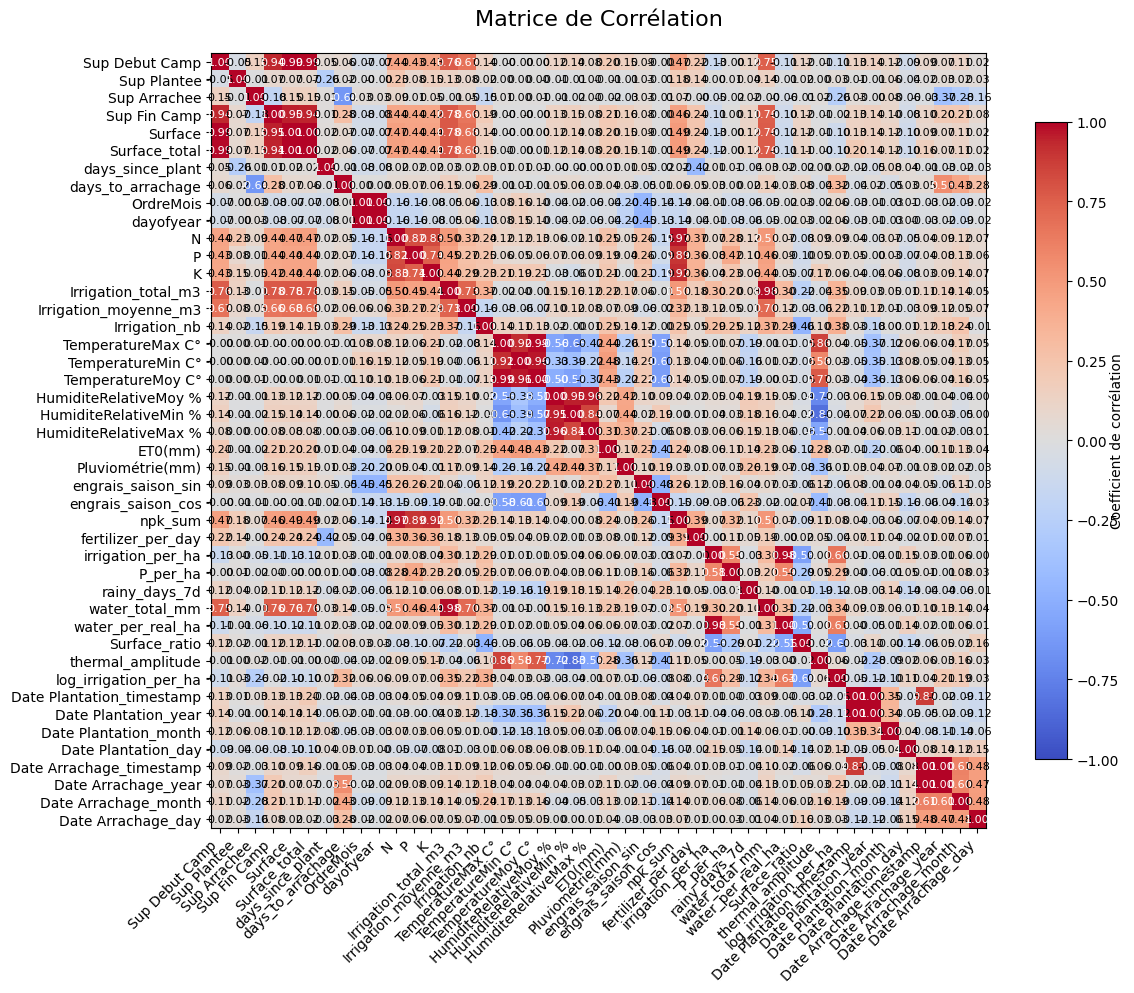

In [82]:
# VERSION ALTERNATIVE - JUSTE LA HEATMAP
print("📈 HEATMAP DE CORRÉLATION BASIQUE")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Sélectionner les données numériques
numeric_data = X.select_dtypes(include=[np.number])

if len(numeric_data.columns) > 0:
    # Calculer la corrélation
    corr_matrix = numeric_data.corr()

    # Créer la figure
    fig, ax = plt.subplots(figsize=(12, 10))

    # Heatmap simple sans masque
    im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)

    # Ajouter les valeurs
    for i in range(len(corr_matrix.columns)):
        for j in range(len(corr_matrix.columns)):
            ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}',
                   ha='center', va='center',
                   color='white' if abs(corr_matrix.iloc[i, j]) > 0.5 else 'black',
                   fontsize=8)

    # Labels
    ax.set_xticks(range(len(corr_matrix.columns)))
    ax.set_yticks(range(len(corr_matrix.columns)))
    ax.set_xticklabels(corr_matrix.columns, rotation=45, ha='right')
    ax.set_yticklabels(corr_matrix.columns)

    # Titre
    ax.set_title('Matrice de Corrélation', fontsize=16, pad=20)

    # Barre de couleur
    cbar = ax.figure.colorbar(im, ax=ax, shrink=0.8)
    cbar.ax.set_ylabel('Coefficient de corrélation', rotation=90, va='bottom')

    plt.tight_layout()
    plt.show()
else:
    print("❌ Aucune donnée numérique disponible")